# Record repair and novelty audit of algorithm bans: `eval.py` demo (novelty audit, section 0c)

**Artifact:** `art_3tH2xtoZ7Gj2`, an evaluation. It is Step 0 of iteration 3 in an AI Inventor study of how **prompt-level algorithm bans** change the algorithm a code model writes. The main model is Qwen3-8B; Llama-3.1-8B-Instruct is a second model family.

**The question in plain words.** Ask an LLM to *"implement a path search"* and it writes BFS almost every time. If you **forbid** BFS in the prompt, does the model come up with something genuinely new, or does it swap in another textbook algorithm? The same question applies to sampling knobs, steering, seeds and explicit *"invent a fully novel algorithm"* instructions. This notebook re-runs the part of the evaluation that answers it from data: the **novelty audit**.

`eval.py` is a CPU-only evaluation. It generates no new programs and uses no GPU. It repairs the iteration-2 record from data on disk, and it audits every *correct* program that fell outside the known-algorithm catalogue. It runs ten sections:

| Section | Step | What it does | Runs here? |
|---|---|---|---|
| `inventory` | S0 | input inventory, label map, de-duplicated row counts | no: needs the 11 dependency artifacts on the run volume |
| `c1` | 0a | C1 likelihood diagnostics (argmax vs landing, implied mass, bootstrap vs replicate noise, AIM null, M arithmetic) | no: needs exp7/exp10 likelihood cells |
| `manifold` | 0b | exp9 activation geometry at the g16 position, with nulls and planted-loop power | no: needs the 0.95 GB exp9 activation states |
| **`judges`** | **0c** | **blind LLM judges for the novelty audit (paid; cached in `audit/judge_cache.jsonl`)** | **yes, from the cached verdicts (no API calls)** |
| **`novelty`** | **0c** | **final classes, Cohen's kappa, controls, manual-pass merge, the novelty answer** | **yes** |
| `llama` | 0d | Llama correct-only compositions and Hill numbers | no: needs exp10/exp11 samples |
| `knob` | 0e | knob table (rarefied Hill-1 at depth 25) | no: needs every per-sample file |
| `positioning` | 0f | dated positioning rows from a web check | no: needs the saved web pages |
| `corrections` | 0h | `corrections.json` (12 record items) | no: needs every section's results |
| `assemble` | – | full/mini/preview `eval_out.json` | no: needs every section's results |

**The demo data.** `mini_demo_data.json` is a curated subset of the novelty-audit dataset:
- **All 78 programs of Set A**, the whole population behind the headline answer. Set A is every unique *correct* program, from any model, experiment or prompt condition, that the automatic labeller could not place in the algorithm catalogue.
- **All 12 B_TOP programs**: programs from exp9's four-algorithm ban that were labelled outside the banned set.
- **10 of the 138 Set B programs**: failing "other" programs from ban conditions, picked for diversity of judge disagreement.
- **The cached verdicts** of the blind judges (A = `openai/gpt-4.1-mini`, B = `google/gemini-2.5-flash`, tie-break C = `deepseek/deepseek-chat`), and the executor's manual reading of the programs.
- **The 15 controls**, plus the task specs, catalogues and reference programs that the judge prompt and the code-similarity check read.

The data was produced by `build_mini_demo_data.py`, which uses the artifact's own selection code. The full selection it rebuilds from all 31,269 programs hashes to the SHA-256 that was committed **before** any judge was called.

**Runtime:** under a minute after the install cell. The two sections run at their original settings; only the Set B sample is smaller than in the full run.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (version pinned in the artifact's requirements.lock.txt)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
# --- eval.py imports (as in the original) ---
from __future__ import annotations

import argparse
import json
import resource
import sys
import time
from pathlib import Path

from loguru import logger

# --- imports of the modules eval.py dispatches to, inlined below: common/paths.py, common/stats.py,
#     sections/s0c_novelty.py and sections/s0c_final.py ---
import ast
import asyncio
import builtins
import hashlib
import math
import os
import random
import re
from collections import Counter, defaultdict
from typing import Any, Iterable, Sequence

import numpy as np
import pandas as pd
from scipy.stats import norm

# --- added for the notebook: module-like namespaces and plots ---
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-3/evaluation-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(f"dataset: {meta['dataset']} | items: " + ", ".join(f"{k} {len(data['selection'][k])}" for k in ("A", "B_TOP", "B"))
      + f" | controls: {meta['n_controls']}")
print(f"cached judge records: {len(data['judge_cache'])} | manual-pass records: {len(data['manual_pass'])} | "
      f"dependency files: {len(data['dependency_files'])}")
print(f"full selection rebuilt from all {meta['n_rows_all_origin_files']:,} origin rows hashes to the pre-judge commit: "
      f"{meta['selection_sha256_matches_commit']}")
print(meta["selection_commit_full"])

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
dataset: novelty_audit | items: A 78, B_TOP 12, B 10 | controls: 15
cached judge records: 264 | manual-pass records: 97 | dependency files: 60
full selection rebuilt from all 31,269 origin rows hashes to the pre-judge commit: True
sha256(audit/selection.jsonl) = c8548bb000c3d79e4d334b14dc78ca3dcd956823e45235bf024bc623db7ea4da
committed_utc = 2026-10-20T17:54:02Z
n_items = 228 (A 78, B_TOP 12, B 138); controls = 15



## Configuration

`eval.py` is a command-line script. Its argument list becomes `EVAL_ARGV` here, because the notebook does not read `sys.argv`. `DEMO_SECTIONS` names the sections whose inputs ship with the notebook.

The two sections that run have only two kinds of knob:
- **Subset size.** How many of the shipped Set A, B_TOP and Set B programs to audit. The defaults below use everything shipped: all of Set A and B_TOP, and 10 of the 138 Set B programs.
- **`KAPPA_N_BOOT`.** The number of bootstrap resamples behind the 95% interval on judge agreement. It is hard-coded to 2000 in `sections/s0c_final.py`.

The other `eval.py` arguments (`--n-boot`, `--n-sim`, `--n-perm`, `--n-null`, `--n-power`, `--workers`) only drive the `c1` and `manifold` sections. Those sections do not run here.

In [5]:
# eval.py command line as a list (same as `uv run eval.py`, i.e. --section all); the demo runs DEMO_SECTIONS of it
EVAL_ARGV = ["--section", "all"]
DEMO_SECTIONS = ["judges", "novelty"]   # the sections whose inputs ship in mini_demo_data.json

# novelty-audit subset: everything shipped in mini_demo_data.json (smallest working run: 3 / 1 / 1)
N_SET_A = 78        # Set A: unique correct out-of-catalogue programs    (shipped and full run: 78)
N_SET_TOP = 12      # B_TOP: exp9 multi:TOP programs outside the ban      (shipped and full run: 12)
N_SET_B = 10        # Set B: failing 'other' programs from ban conditions (shipped: 10; full run: 138)

KAPPA_N_BOOT = 2000   # bootstrap resamples for the kappa 95% CI (original value: 2000; smallest working run: 10)

## `common/paths.py`: locations and JSON helpers

This is the artifact's path module, copied as is, with two changes for the notebook:
- **`WS`**, the repository root in the original, becomes `./eval_demo_outputs`, so every file the sections write lands in one folder next to the notebook.
- **`RUNS`**, the AI Inventor run-volume root, gets a default that works on any machine. The original default, `WS.parents[4]`, assumes the AI Inventor folder layout. The demo never uses `RUNS`.

Every dependency is cited as `<artifact_id>:<relative path>`. `dep_root()` looks for a dependency first in `$AII_DEPS_ROOT/<artifact_id>`, and the next cell unpacks the shipped dependency files into exactly that place.

In [6]:
"""Workspace and dependency locations, resolved relative to this repository (no absolute server paths).

Every dependency is read in place, read-only. A dependency is addressed as `<artifact_id>:<relative path>` in all
outputs; `src(aid, rel)` builds that citation string and `dep(aid, rel)` the readable Path.
"""

WS = Path.cwd() / "eval_demo_outputs"   # DEMO: all outputs in one folder (original: Path(__file__).resolve().parent.parent)
# runs root = <runs>/<run>/3_invention_loop/iter_3/gen_art/<this workspace>; overridable for a fork
RUNS = Path(os.environ.get("AII_RUNS_ROOT", str(WS / "runs")))   # DEMO default (original: str(WS.parents[4]))

DEPS: dict[str, str] = {
    "art__skdlFp_o3e9": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_1",   # exp1
    "art_D6Z0Snf09sFL": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_2",   # exp2
    "art_U5UKkFrOgSsE": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_4",   # exp4
    "art_HF8nK8B_Lqyy": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_5",   # exp5
    "art_UoCVh2Qe5RZ0": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_6",   # exp6
    "art_6zBfl3kDjeiP": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_7",   # exp7
    "art_8_ULPE8jJQc_": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_8",   # exp8
    "art_IVZc3TWCeE9f": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_9",   # exp9
    "art_-QPYRaFERCBX": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_10",  # exp10
    "art_0ndRfWKBWclR": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_11",  # exp11
    "art_3iv5G76C3yoX": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_12",  # exp12
}
EXP = {"exp1": "art__skdlFp_o3e9", "exp2": "art_D6Z0Snf09sFL", "exp4": "art_U5UKkFrOgSsE", "exp5": "art_HF8nK8B_Lqyy",
       "exp6": "art_UoCVh2Qe5RZ0", "exp7": "art_6zBfl3kDjeiP", "exp8": "art_8_ULPE8jJQc_", "exp9": "art_IVZc3TWCeE9f",
       "exp10": "art_-QPYRaFERCBX", "exp11": "art_0ndRfWKBWclR", "exp12": "art_3iv5G76C3yoX",
       "exp3": "art_8_ULPE8jJQc_"}   # exp3 programs are read only through the pools copy shipped inside exp8
REPORT_REL = "run_aRfWvcSWjssb/3_invention_loop/iter_3/gen_strat/current_report.md"  # iteration-2 report (old wording)

RESULTS = WS / "results"
TABLES = WS / "tables"
FIGS = WS / "figures"
AUDIT = WS / "audit"
LOGS = WS / "logs"
SEED = 20261020


DEPS_ROOT_ENV = "AII_DEPS_ROOT"  # optional: a directory holding one folder per dependency, named by its artifact id


def dep_root(aid: str) -> Path:
    """Folder of dependency `aid`, looked up in this order:
    1. $AII_DEPS_ROOT/<artifact_id>;
    2. ../<artifact_id> (the published repository: every artifact is a sibling folder named by its id);
    3. the AI Inventor run-volume layout, relative to this repository (RUNS / DEPS[aid])."""
    env = os.environ.get(DEPS_ROOT_ENV)
    if env:
        return Path(env) / aid
    sib = WS.parent / aid
    if sib.is_dir():
        return sib
    return RUNS / DEPS[aid]


def dep(aid_or_exp: str, rel: str = "") -> Path:
    aid = EXP.get(aid_or_exp, aid_or_exp)
    return dep_root(aid) / rel


def src(aid_or_exp: str, rel: str) -> str:
    aid = EXP.get(aid_or_exp, aid_or_exp)
    return f"{aid}:{rel}"


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    out = []
    with Path(p).open() as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    continue
    return out


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def _default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        v = float(o)
        return None if not math.isfinite(v) else v
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o)
    return str(o)


def clean(o: Any) -> Any:
    """Recursively replace non-finite floats by None so the JSON is standard."""
    import numpy as np

    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)):
        v = float(o)
        return v if math.isfinite(v) else None
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(clean(obj), indent=indent, default=_default))
    tmp.replace(p)


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(clean(r), default=_default) + "\n")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def code_key(code: str) -> str:
    """De-duplication key: sha256 of the code with trailing whitespace stripped from every line and the ends."""
    norm = "\n".join(line.rstrip() for line in (code or "").strip().splitlines())
    return sha256_text(norm)

## Unpack the demo data into the folder layout `eval.py` reads

The original sections read four kinds of file:
1. the judge cache, `audit/judge_cache.jsonl`;
2. the executor's manual pass, `audit/manual_pass.jsonl`;
3. the task specs and catalogue reference programs inside the exp1, exp9 and exp11 artifacts;
4. the per-program sample files of 11 artifacts, used only to build the selection.

This cell writes the first three from `mini_demo_data.json` to the places where the original code looks for them: `eval_demo_outputs/audit/` and `$AII_DEPS_ROOT/<artifact_id>/…`. Most of the section code then runs unchanged. The fourth kind, all 31,269 per-program rows, is not shipped. `build_selection()` therefore returns the shipped subset of the committed selection (see below).

In [7]:
# output folders the sections write into (in the artifact repository they already exist)
for d in (RESULTS, TABLES, FIGS, AUDIT, LOGS):
    d.mkdir(parents=True, exist_ok=True)

# task specs + catalogue reference programs -> $AII_DEPS_ROOT/<artifact_id>/<relative path> (dep_root's first choice)
DEPS_DIR = WS / "deps"
for rel, text in data["dependency_files"].items():
    p = DEPS_DIR / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text)
os.environ[DEPS_ROOT_ENV] = str(DEPS_DIR)

# the audit files: every cached judge response (with its cost) and the executor's manual pass
write_jsonl(AUDIT / "judge_cache.jsonl", data["judge_cache"])
write_jsonl(AUDIT / "manual_pass.jsonl", data["manual_pass"])

by_art = Counter(k.split("/")[0] for k in data["dependency_files"])
print(f"{len(data['dependency_files'])} dependency files unpacked under {DEPS_DIR.relative_to(Path.cwd())}/: {dict(by_art)}")
print(f"dep('exp1', 'tasks/t1_grid/spec.txt') -> {dep('exp1', 'tasks/t1_grid/spec.txt').relative_to(Path.cwd())}")
print(f"audit files: {sorted(p.name for p in AUDIT.iterdir())}")

60 dependency files unpacked under eval_demo_outputs/deps/: {'art__skdlFp_o3e9': 24, 'art_IVZc3TWCeE9f': 25, 'art_0ndRfWKBWclR': 11}
dep('exp1', 'tasks/t1_grid/spec.txt') -> eval_demo_outputs/deps/art__skdlFp_o3e9/tasks/t1_grid/spec.txt
audit files: ['judge_cache.jsonl', 'manual_pass.jsonl']


## `common/stats.py`: Wilson interval and Cohen's kappa

The artifact's statistics module also holds Newcombe intervals, Hill numbers, Kish ESS and the PSIS k-hat, which other sections use. The novelty audit imports only two functions, copied unchanged:
- **`wilson(k, n)`**: the Wilson score interval for a proportion.
- **`cohen_kappa(a, b)`**: chance-corrected agreement between two raters. It is 1 for perfect agreement and 0 for chance level; 0.21–0.40 is conventionally called "fair" and 0.41–0.60 "moderate".

In [8]:
def wilson(k: int, n: int, conf: float = 0.95) -> tuple[float, float]:
    if n <= 0:
        return (math.nan, math.nan)
    z = norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float:
    a, b = list(a), list(b)
    n = len(a)
    if n == 0:
        return math.nan
    cats = sorted(set(a) | set(b))
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[c] * cb[c] for c in cats) / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else (1.0 if po == 1 else math.nan)

## `eval.py`: logging, the section list and the row loader

This is the top of `eval.py`, copied as is. Logs go to stdout and to `logs/run.log`, and `SECTIONS` is the full list of ten sections.

The one change is `_rows()`. The original normalises every per-program record of the 11 origin artifacts with `common.rows.iter_rows`: 31,269 programs covering both models and every experiment and condition. Those files stay on the AI Inventor run volume, so in the demo `_rows()` returns an empty list. The two sections then fall back to the shipped subset, at three places marked `DEMO`.

In [9]:
LOGS.mkdir(parents=True, exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "run.log"), rotation="30 MB", level="DEBUG")

SECTIONS = ["inventory", "c1", "manifold", "judges", "novelty", "llama", "knob", "positioning", "corrections",
            "assemble"]


def _rows(include_extra: bool = False):
    # DEMO: the original is
    #     from common.rows import iter_rows
    #     return list(iter_rows(include_exp12_extra=include_extra))
    # which reads the 31,269 per-program records of the 11 origin artifacts on the run volume (not shipped)
    return []

## Section 0c, part 1: judges, catalogues and classes (`sections/s0c_novelty.py`)

Each out-of-catalogue program goes in front of **two blind judges from different model families**: A, `openai/gpt-4.1-mini`, and B, `google/gemini-2.5-flash`. When their classes differ, **C**, `deepseek/deepseek-chat`, breaks the tie. No Qwen or Llama model judges, because those are the models under study.

A judge sees three things: the task spec, a **catalogue of known algorithms** with one line of mechanism each (`T1_CAT` for the grid path-search task t1, `T2_CAT` for weighted shortest paths t2), and the code. It never sees which model wrote the program, under which prompt, or whether the program passed the tests.

Each judge picks one of four classes:
- `LABELLER_MISS`: a catalogue algorithm in disguise;
- `CATALOGUE_VARIANT`: a named hybrid or variant of a known algorithm;
- `NOVEL_ALGORITHM`: matches no catalogue or textbook algorithm;
- `DEGENERATE_OR_HARDCODED`: brute force, special-casing or literal outputs.

`INSTRUCTION_CONDS` flags prompt conditions that explicitly asked for novelty, for example `instr_`, `creative`, `new_algo` and `fully_novel`. The code is unchanged.

In [10]:
JUDGES = {"A": "openai/gpt-4.1-mini", "B": "google/gemini-2.5-flash", "C": "deepseek/deepseek-chat"}
PRICE = {"openai/gpt-4.1-mini": (0.40, 1.60), "google/gemini-2.5-flash": (0.30, 2.50),
         "deepseek/deepseek-chat": (0.2574, 1.0287)}       # USD per M tokens (in, out), verified 2026-10-20
COST_STOP_USD = 1.30
CLASSES = ["NOVEL_ALGORITHM", "CATALOGUE_VARIANT", "LABELLER_MISS", "DEGENERATE_OR_HARDCODED"]
CACHE = AUDIT / "judge_cache.jsonl"
SET_B_MAX = 150

# one-line mechanism definitions: exp9 common.py MODE_DEFINITIONS (verbatim) + textbook neighbours named in the plan
T1_CAT = {
    "BFS": "breadth-first search: explores cells in order of distance from start with a FIFO queue (deque.popleft, list.pop(0), queue.Queue) or level-by-level frontier lists; one search direction; no priority queue.",
    "DFS": "depth-first search: follows one branch as deep as possible with recursion or a LIFO stack, with a visited set; a single pass with no depth limit and no restarts (neighbour ordering by distance is still DFS).",
    "bidirectional BFS": "two breadth-first searches, one from start and one from goal, expanded alternately until the frontiers meet; the path is joined at the meeting cell; no heuristic, no heap.",
    "IDDFS": "iterative deepening DFS: repeated depth-limited depth-first searches with an increasing depth limit (0, 1, 2, ...) until the goal is found; no heuristic bound.",
    "A*": "a priority queue (heap) ordered by f = g + h, cost so far plus a heuristic such as the Manhattan distance to the goal; one search direction.",
    "greedy best-first search": "a priority queue ordered by the heuristic h alone (e.g. Manhattan distance to the goal), ignoring the cost so far; one search direction.",
    "IDA*": "repeated depth-first searches bounded by f = g + h, raising the bound to the smallest f that exceeded it, until the goal is found.",
    "JPS (jump point search)": "A*-style search that jumps along straight lines and adds cells to the open list only at jump points (turning points next to walls, or the goal).",
    "bidirectional A*": "two A* searches, forward from start and backward from goal, each with its own heuristic-ordered heap, stopping when the frontiers meet.",
    "unit-weight Dijkstra": "a priority queue (heap) ordered by distance from start only, with no heuristic toward the goal.",
    "textbook neighbours": "beam search; random walk; wall following (left/right-hand rule); Lee wavefront (BFS distance labelling then backtrace); bidirectional Dijkstra on the grid.",
}
T2_CAT = {
    "Dijkstra's algorithm": "a single priority queue (heap) of tentative distances from s, popping the smallest distance each time (lazy deletion or decrease-key variants), one search direction.",
    "Bellman-Ford / SPFA": "Bellman-Ford (repeated relaxation passes over all edges, up to n-1 rounds, possibly with early exit) or SPFA (a FIFO queue of nodes whose distance improved, often with an in-queue flag).",
    "bidirectional Dijkstra": "two Dijkstra searches, forward from s on the graph and backward from t on the reversed graph, with a meeting/stopping rule.",
    "Floyd-Warshall": "all-pairs shortest paths with a triple loop over k, i, j updating dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j]).",
    "Dial's algorithm": "Dijkstra with a bucket queue: an array or dict of buckets indexed by distance, scanned in increasing distance order instead of a binary heap.",
    "DAG dynamic programming": "topological order then one relaxation pass (only valid on acyclic graphs).",
    "textbook neighbours": "Johnson's algorithm; A* with a non-zero heuristic; 0-1 BFS / deque-based shortest path; BFS ignoring weights; exhaustive DFS enumeration of all simple paths; memoised DFS over (node) states.",
}
INSTRUCTION_CONDS = re.compile(r"(instr_|creative|new_algo|fully_novel|enumerat|steer:dc|decommit|novelty|nonce|removal:)",
                               re.I)

SYSTEM = ("You are an expert in algorithms and program analysis. You classify the algorithmic MECHANISM of a Python "
          "program written for a stated task. You are not told who wrote it or why. Answer with one JSON object only.")

## Section 0c, part 2: which programs are audited (`build_selection`)

The selection was fixed, and its SHA-256 committed, **before** any judge was called:
- **Set A**: every unique **correct** program that the labeller put in "other" or "other_ext". These programs pass the hidden tests but are not recognised as a catalogue algorithm. This is the population the novelty answer is about. It spans both models, every experiment and every condition: bans, steering, seeds, decoding knobs and "invent a new algorithm" instructions. Duplicates are merged by task and the SHA-256 of the whitespace-normalised code.
- **B_TOP**: every program from exp9's `multi:TOP` condition, which bans BFS, DFS, GBFS and IDDFS together, that was labelled outside the banned set.
- **Set B**: up to 150 failing "other" programs from ban conditions, stratified by experiment, task, model and ban family.

The function body below is the original. In the demo it receives no rows, so a guard at the top (marked `DEMO`) returns the shipped subset of the committed selection instead. `build_mini_demo_data.py` rebuilt that selection from all 31,269 rows with exactly this function, and checked that it hashes to the committed `c8548bb0…`. The subset sizes come from the config cell, and the `counts_*` fields are computed on the subset with the original expressions.

In [11]:
# ------------------------------------------------------------------------------------------------ selection
def _ban_family(r: dict[str, Any]) -> str | None:
    c = r["condition"]
    if r["exp"] == "exp9":
        if c.startswith("multi:"):
            return "multi"
        if c.startswith("los:"):
            return "leave_one_survivor"
        if c.startswith("single:"):
            return "single"
        return None
    if r["exp"] == "exp10" and c.startswith("twostep"):
        return "two_step"
    if c.startswith("succession") or ("+" in c and c.startswith("ban:")):
        return "two_step"
    if r["banned_set"]:
        return "single"
    return None


def build_selection(rows: list[dict[str, Any]], set_b_max: int = SET_B_MAX) -> dict[str, Any]:
    if not rows:   # DEMO: no per-program rows shipped -> the shipped subset of the committed selection
        s = data["selection"]
        A, TOP, B = s["A"][:N_SET_A], s["B_TOP"][:N_SET_TOP], s["B"][:N_SET_B]
        return {"A": A, "B_TOP": TOP, "B": B, "strata": s["strata"],
                "counts_with_duplicates": {"A": sum(i["n_copies"] for i in A), "B_TOP": sum(i["n_copies"] for i in TOP),
                                           "B": sum(i["n_copies"] for i in B)},
                "counts_unique": {"A": len(A), "B_TOP": len(TOP), "B": len(B)}}
    rng = random.Random(SEED)
    by_key: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for r in rows:
        if r["dedup_key"]:
            by_key[r["dedup_key"]].append(r)

    def item(key: str, set_name: str) -> dict[str, Any]:
        prov = by_key[key]
        r0 = prov[0]
        return {"item_id": f"{set_name}|{key[:3]}{sha256_text(key)[:14]}", "set": set_name, "dedup_key": key,
                "task": r0["task"], "code": r0["code"], "label": r0["label"], "label_fine": r0["label_fine"],
                "passed": r0["passed"], "models": sorted({p["model"] for p in prov}),
                "exps": sorted({p["exp"] for p in prov}), "conditions": sorted({p["condition"] for p in prov}),
                "provenance": [{"source": p["source"], "line": p["line"], "condition": p["condition"],
                                "label": p["label_fine"], "passed": p["passed"]} for p in prov],
                "n_copies": len(prov)}

    setA_keys = sorted({r["dedup_key"] for r in rows if r["dedup_key"] and r["label"] in ("other", "other_ext")
                        and r["passed"] is True})
    A = [item(k, "A") for k in setA_keys]
    # exp9 multi:TOP programs outside the banned set (any label, any pass status)
    top_keys = []
    for r in rows:
        if r["exp"] == "exp9" and r["condition"] == "multi:TOP" and r["dedup_key"]:
            lab9 = r["label_fine"] if r["label_fine"] in ("astar", "gbfs") else r["label"]
            if lab9 not in r["banned_set"] and r["label"] != "unparseable" and r["dedup_key"] not in setA_keys:
                top_keys.append(r["dedup_key"])
    top_keys = sorted(set(top_keys))
    TOP = [item(k, "B_TOP") for k in top_keys]
    # failing 'other' programs from ban conditions, stratified (exp, task, model, ban family)
    taken = set(setA_keys) | set(top_keys)
    strata: dict[tuple, list[str]] = defaultdict(list)
    for r in rows:
        if (r["dedup_key"] and r["label"] == "other" and r["passed"] is False and r["dedup_key"] not in taken):
            fam = _ban_family(r)
            if fam:
                strata[(r["exp"], r["task"], r["model"], fam)].append(r["dedup_key"])
    for k in strata:
        strata[k] = sorted(set(strata[k]))
    budget = max(0, set_b_max - len(TOP))
    tot = sum(len(v) for v in strata.values())
    alloc = {}
    for k, v in strata.items():
        alloc[k] = min(len(v), max(5, int(round(budget * len(v) / max(1, tot)))))
    while sum(alloc.values()) > budget:          # trim the largest allocation first, never below 5 (or availability)
        kmax = max(alloc, key=lambda k: (alloc[k], str(k)))
        if alloc[kmax] <= 5:
            break
        alloc[kmax] -= 1
    B = []
    for k in sorted(strata, key=str):
        keys = list(strata[k])
        rng.shuffle(keys)
        for key in keys[:alloc[k]]:
            if key not in taken:
                taken.add(key)
                it = item(key, "B")
                it["stratum"] = "|".join(map(str, k))
                B.append(it)
    return {"A": A, "B_TOP": TOP, "B": B,
            "strata": {"|".join(map(str, k)): {"available": len(v), "allocated": alloc[k]} for k, v in strata.items()},
            "counts_with_duplicates": {"A": sum(i["n_copies"] for i in A), "B_TOP": sum(i["n_copies"] for i in TOP),
                                       "B": sum(i["n_copies"] for i in B)},
            "counts_unique": {"A": len(A), "B_TOP": len(TOP), "B": len(B)}}

## Section 0c, part 3: controls that gate trust in the judges

Before anyone believes the judges, they are tested on programs whose right answer is known:
- **10 positive controls**: catalogue reference implementations of BFS, DFS, bidirectional BFS, IDDFS, A*, Dijkstra, Bellman-Ford, Floyd-Warshall, Dial and bidirectional Dijkstra. An AST transformer renames every identifier to `v1, v2, …` and strips docstrings. The expected verdict is `LABELLER_MISS` with the right algorithm named.
- **5 negative controls**: degenerate programs, either hard-coded answers or brute-force enumeration of permutations. The expected verdict is `DEGENERATE_OR_HARDCODED`.

The gate passes at ≥ 9/10 positives and ≥ 4/5 negatives. The code is unchanged. It reads the reference programs through `dep()`, from the files unpacked above. The two lines at the end, added for the notebook, show one renamed control.

In [12]:
# ------------------------------------------------------------------------------------------------ controls
class _Renamer(ast.NodeTransformer):
    KEEP = set(dir(builtins)) | {"solve", "self", "heapq", "deque", "collections", "math", "sys", "itertools",
                                 "functools", "defaultdict", "heappush", "heappop", "heapify", "inf", "lru_cache",
                                 "Counter", "queue", "Queue", "PriorityQueue", "bisect", "typing", "List", "Tuple",
                                 "Optional", "Dict", "Set", "float", "heapreplace", "OrderedDict", "array"}

    def __init__(self) -> None:
        self.map: dict[str, str] = {}

    def _n(self, name: str) -> str:
        if name in self.KEEP:
            return name
        if name not in self.map:
            self.map[name] = f"v{len(self.map) + 1}"
        return self.map[name]

    def visit_Name(self, node: ast.Name) -> ast.AST:
        node.id = self._n(node.id)
        return node

    def visit_arg(self, node: ast.arg) -> ast.AST:
        node.arg = self._n(node.arg)
        node.annotation = None
        return node

    def visit_FunctionDef(self, node: ast.FunctionDef) -> ast.AST:
        node.name = self._n(node.name)
        node.returns = None
        if node.body and isinstance(node.body[0], ast.Expr) and isinstance(getattr(node.body[0], "value", None),
                                                                           ast.Constant) \
                and isinstance(node.body[0].value.value, str):
            node.body = node.body[1:] or [ast.Pass()]
        self.generic_visit(node)
        return node


def rename_code(code: str) -> str:
    tree = ast.parse(code)
    if tree.body and isinstance(tree.body[0], ast.Expr) and isinstance(getattr(tree.body[0], "value", None),
                                                                       ast.Constant):
        tree.body = tree.body[1:]
    tree = _Renamer().visit(tree)
    ast.fix_missing_locations(tree)
    return ast.unparse(tree)


POS_CONTROLS = [("t1", "bfs_deque_parent.py", "bfs"), ("t1", "dfs_stack.py", "dfs"), ("t1", "bibfs_sets.py", "bibfs"),
                ("t1", "iddfs_iterative.py", "iddfs"), ("t1", "astar_fg.py", "astar"),
                ("t2", "dijkstra_lazy.py", "dijkstra"), ("t2", "bellman_ford.py", "bf_spfa"),
                ("t2", "floyd_inf.py", "floyd"), ("t2", "dial_list.py", "dial"),
                ("t2", "bidijkstra_alternate.py", "bidijkstra")]

NEG_CONTROLS = [
    ("t1", "def solve(grid, start, goal):\n    if start == goal:\n        return [start]\n    known = {((0, 0), (0, 2)): [(0, 0), (0, 1), (0, 2)], ((0, 0), (2, 0)): [(0, 0), (1, 0), (2, 0)]}\n    if (tuple(start), tuple(goal)) in known:\n        return known[(tuple(start), tuple(goal))]\n    if len(grid) == 1 and len(grid[0]) == 2:\n        return [start, goal]\n    return []\n"),
    ("t1", "import itertools\n\ndef solve(grid, start, goal):\n    free = [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == '.']\n    if start not in free or goal not in free:\n        return []\n    if start == goal:\n        return [start]\n    middle = [p for p in free if p != start and p != goal]\n    for k in range(len(middle) + 1):\n        for combo in itertools.permutations(middle, k):\n            path = [start, *combo, goal]\n            if all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(path, path[1:])):\n                return list(path)\n    return []\n"),
    ("t2", "def solve(n, edges, s, t):\n    table = {(2, 0, 1): 5, (3, 0, 2): 7, (4, 0, 3): 9}\n    if s == t:\n        return 0\n    if (n, s, t) in table:\n        return table[(n, s, t)]\n    if not edges:\n        return -1\n    return min(w for (u, v, w) in edges if u == s and v == t) if any(u == s and v == t for u, v, _ in edges) else -1\n"),
    ("t2", "import itertools\n\ndef solve(n, edges, s, t):\n    if s == t:\n        return 0\n    w = {}\n    for u, v, c in edges:\n        if (u, v) not in w or c < w[(u, v)]:\n            w[(u, v)] = c\n    best = -1\n    others = [x for x in range(n) if x not in (s, t)]\n    for k in range(len(others) + 1):\n        for mid in itertools.permutations(others, k):\n            path = [s, *mid, t]\n            if all((a, b) in w for a, b in zip(path, path[1:])):\n                cost = sum(w[(a, b)] for a, b in zip(path, path[1:]))\n                if best < 0 or cost < best:\n                    best = cost\n    return best\n"),
    ("t2", "def solve(n, edges, s, t):\n    if s == t:\n        return 0\n    answers = {0: -1, 1: 4, 2: 10, 3: 17, 4: 3}\n    return answers.get((n * 7 + len(edges) * 3 + s + t) % 5, -1)\n"),
]


def build_controls() -> list[dict[str, Any]]:
    out = []
    for task, fname, lab in POS_CONTROLS:
        d = "t1_grid" if task == "t1" else "t2_wsp"
        code = (dep("exp1", f"tasks/{d}/references/{fname}")).read_text()
        out.append({"item_id": f"CTRL_POS|{task}|{lab}", "set": "control_pos", "task": task, "code": rename_code(code),
                    "expected_class": "LABELLER_MISS", "expected_match": lab,
                    "source": src("exp1", f"tasks/{d}/references/{fname}")})
    for i, (task, code) in enumerate(NEG_CONTROLS):
        out.append({"item_id": f"CTRL_NEG|{task}|{i}", "set": "control_neg", "task": task, "code": code,
                    "expected_class": "DEGENERATE_OR_HARDCODED", "expected_match": None, "source": "hand-written"})
    return out


# notebook: show what a judge sees for one positive control (the bidirectional-BFS reference, renamed)
_ctrl = {c["item_id"]: c for c in build_controls()}
print(f"{len(_ctrl)} controls; {_ctrl['CTRL_POS|t1|bibfs']['source']} after renaming:\n\n{_ctrl['CTRL_POS|t1|bibfs']['code']}")

15 controls; art__skdlFp_o3e9:tasks/t1_grid/references/bibfs_sets.py after renaming:

def solve(v1, v2, v3):
    v4, v5 = (len(v1), len(v1[0]))
    if v1[v2[0]][v2[1]] == '#' or v1[v3[0]][v3[1]] == '#':
        return []
    if v2 == v3:
        return [v2]

    def v6(v7):
        v8, v9 = v7
        for v10, v11 in ((v8 - 1, v9), (v8 + 1, v9), (v8, v9 - 1), (v8, v9 + 1)):
            if 0 <= v10 < v4 and 0 <= v11 < v5 and (v1[v10][v11] == '.'):
                yield (v10, v11)
    v12, v13 = ({v2}, {v3})
    v14, v15 = ({v2: None}, {v3: None})
    v16 = None
    while v12 and v13 and (v16 is None):
        if len(v12) <= len(v13):
            v17 = set()
            for v7 in v12:
                for v18 in v6(v7):
                    if v18 not in v14:
                        v14[v18] = v7
                        v17.add(v18)
                        if v18 in v15:
                            v16 = v18
            v12 = v17
        else:
            v17 = set()
            for v7 in 

## Section 0c, part 4: the blind judge prompt

`build_prompt` puts together the task spec, the known-algorithm catalogue for the task, the four class definitions and the program.
- For the grid task t1 and the weighted shortest-path task t2, the catalogue is the one-line mechanism list above.
- Bench tasks such as T03 (k-th smallest) and T13 (merge intervals) use the catalogue in the exp11 bench `spec.json`.

The code is unchanged.

In [13]:
# ------------------------------------------------------------------------------------------------ prompt
_BENCH_DIRS: dict[str, Any] = {}


def bench_spec(task: str) -> tuple[str, dict[str, str]]:
    if not _BENCH_DIRS:
        for d in dep("exp11", "bench").iterdir():
            if d.is_dir() and (d / "spec.json").exists():
                _BENCH_DIRS[d.name.split("_")[0]] = d
    s = read_json(_BENCH_DIRS[task] / "spec.json")
    cat = s["catalogue"]
    if isinstance(cat, str):
        cat = ast.literal_eval(cat)
    return s["spec_text"], {c["display_name"]: c["mechanism"] for c in cat}


def spec_and_catalogue(task: str) -> tuple[str, dict[str, str]]:
    if task == "t1":
        return dep("exp1", "tasks/t1_grid/spec.txt").read_text().strip(), T1_CAT
    if task == "t2":
        return dep("exp1", "tasks/t2_wsp/spec.txt").read_text().strip(), T2_CAT
    return bench_spec(task)


def build_prompt(task: str, code: str) -> str:
    spec, cat = spec_and_catalogue(task)
    cat_lines = "\n".join(f"- {k}: {v}" for k, v in cat.items())
    return (f"TASK SPECIFICATION\n{spec}\n\nKNOWN-ALGORITHM CATALOGUE (one line of mechanism per entry)\n{cat_lines}\n\n"
            "CLASSES\n"
            "LABELLER_MISS: the program IS one of the catalogue algorithms above, possibly renamed or disguised "
            "(different identifiers, a queue built from a list, a stack replaced by recursion, extra checks).\n"
            "CATALOGUE_VARIANT: a hybrid or variant of a catalogue algorithm or of another textbook algorithm; you must "
            "name it.\n"
            "NOVEL_ALGORITHM: the mechanism matches no catalogue algorithm and no textbook algorithm you know.\n"
            "DEGENERATE_OR_HARDCODED: brute-force enumeration of candidates, special-casing of particular inputs, or "
            "literal outputs instead of an algorithm.\n"
            "Classify the MECHANISM only. The program may or may not be correct; correctness does not matter.\n\n"
            f"PROGRAM\n```python\n{code.strip()}\n```\n\n"
            "Return one JSON object with exactly these keys: \"class\" (one of LABELLER_MISS, CATALOGUE_VARIANT, "
            "NOVEL_ALGORITHM, DEGENERATE_OR_HARDCODED), \"catalogue_match\" (the catalogue entry name, or null), "
            "\"closest_known_algorithm\" (string), \"mechanism_summary\" (at most 40 words), \"rationale\" (at most 80 "
            "words), \"confidence\" (number between 0 and 1).")

### Check: each cached verdict belongs to exactly this prompt

The judge cache is keyed by `(judge, item_id, sha256(prompt))`. The cell below, added for the notebook, does three things for the first Set A program:
1. rebuilds its prompt and prints it in full;
2. looks up the cached verdicts under the prompt's hash;
3. prints what each judge answered.

A hit proves that the stored answer was given to this blind prompt, rebuilt from the shipped spec, catalogue and code. Both sections look up every item this way.

In [14]:
_it = data["selection"]["A"][0]
_prompt = build_prompt(_it["task"], _it["code"])
_sha = sha256_text(_prompt)
_cached = {r["judge"]: r for r in data["judge_cache"] if r["item_id"] == _it["item_id"] and r["prompt_sha"] == _sha}
print(f"item {_it['item_id']} | task {_it['task']} | models {_it['models']} | conditions {_it['conditions']} | "
      f"passed {_it['passed']}")
print(f"prompt: {len(_prompt):,} characters, sha256 {_sha[:16]}... -> cached verdicts from judges {sorted(_cached)}")
print("\n----- SYSTEM -----\n" + SYSTEM + "\n----- USER -----\n" + _prompt + "\n------------------\n")
for j, r in sorted(_cached.items()):
    pj = r["parsed"]
    print(f"judge {j} ({r['model']}): {pj['class']} | catalogue match: {pj.get('catalogue_match')} | "
          f"closest known: {pj.get('closest_known_algorithm')} | cost ${r['cost']:.5f}")

item A|T03c7307628da45b8 | task T03 | models ['Qwen/Qwen3-8B'] | conditions ['forced'] | passed True
prompt: 2,732 characters, sha256 669afabf6e0489e3... -> cached verdicts from judges ['A', 'B', 'C']

----- SYSTEM -----
You are an expert in algorithms and program analysis. You classify the algorithmic MECHANISM of a Python program written for a stated task. You are not told who wrote it or why. Answer with one JSON object only.
----- USER -----
TASK SPECIFICATION
Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code b

## Section 0c, part 5: judge calls, response parsing and the cache

These are the original asynchronous OpenRouter calls, shown unchanged:
- **Settings**: temperature 0, at most 400 output tokens, JSON mode, at most 8 calls in flight.
- **Stage 1**: judges A and B classify every item. **Stage 2**: C classifies the items where A and B disagree.
- **Budget**: a spend counter stops every call at USD 1.30, and the run also stops at the first "per-run budget" refusal.
- **Caching**: every response is appended to `audit/judge_cache.jsonl` together with its cost.

**The demo calls no API.** `sec_judges` below runs the original cache-only branch, `call_judges=False`. All 115 judged items, 100 programs plus 15 controls, are in the cache, so the original with `--reuse-judge-cache` would also make zero new calls. The whole audit cost USD 0.415.

`_parse` turns a judge's raw text into the class JSON, and `load_cache` reads the cache; both are unchanged. The last lines of the cell, added for the notebook, re-parse every cached raw response and check that the stored class comes back.

In [15]:
# ------------------------------------------------------------------------------------------------ judge calls
class Budget:
    def __init__(self, spent: float = 0.0) -> None:
        self.spent = spent
        self.stop = False
        self.reason = ""
        self.n_calls = 0


def _parse(text: str) -> dict[str, Any] | None:
    if not text:
        return None
    t = text.strip()
    m = re.search(r"\{.*\}", t, re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    c = str(d.get("class", "")).strip().upper().replace(" ", "_")
    if c not in CLASSES:
        for k in CLASSES:
            if k.split("_")[0] in c:
                c = k
                break
    d["class"] = c if c in CLASSES else None
    return d


def load_cache() -> dict[tuple[str, str, str], dict[str, Any]]:
    out = {}
    if CACHE.exists():
        for r in read_jsonl(CACHE):
            out[(r["judge"], r["item_id"], r["prompt_sha"])] = r
    return out


async def _call(client: Any, sem: asyncio.Semaphore, budget: Budget, judge: str, item: dict[str, Any],
                prompt: str, cache_fh: Any) -> dict[str, Any] | None:
    model = JUDGES[judge]
    async with sem:
        if budget.stop or budget.spent >= COST_STOP_USD:   # checked AFTER acquiring the slot
            budget.stop = True
            return None
        extra: dict[str, Any] = {"usage": {"include": True}}
        if judge == "B":
            extra["reasoning"] = {"max_tokens": 0, "exclude": True}
        for attempt in range(3):
            if budget.stop:
                return None
            try:
                t0 = time.time()
                resp = await client.chat.completions.create(
                    model=model, temperature=0, max_tokens=400, response_format={"type": "json_object"},
                    messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}],
                    extra_body=extra, timeout=90)
                text = resp.choices[0].message.content or ""
                u = resp.usage
                cost = None
                if u is not None:
                    cost = getattr(u, "cost", None)
                    if cost is None and getattr(u, "model_extra", None):
                        cost = u.model_extra.get("cost")
                    if cost is None:
                        pi, po = PRICE[model]
                        cost = (u.prompt_tokens * pi + u.completion_tokens * po) / 1e6
                cost = float(cost or 0.0)
                budget.spent += cost
                budget.n_calls += 1
                parsed = _parse(text)
                rec = {"judge": judge, "model": model, "item_id": item["item_id"], "prompt_sha": sha256_text(prompt),
                       "parsed": parsed, "raw": text[:2000], "cost": cost, "seconds": round(time.time() - t0, 2),
                       "prompt_tokens": getattr(u, "prompt_tokens", None), "completion_tokens":
                           getattr(u, "completion_tokens", None), "utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
                cache_fh.write(json.dumps(rec) + "\n")
                cache_fh.flush()
                logger.debug(f"judge {judge} {item['item_id']} -> {parsed and parsed.get('class')} ${cost:.5f} "
                             f"(total ${budget.spent:.4f})")
                if parsed is None and attempt < 2:
                    continue
                return rec
            except Exception as e:      # noqa: BLE001 - provider errors are heterogeneous; 403 budget handled below
                msg = str(e)
                if "AI Inventor per-run OpenRouter budget" in msg or "403" in msg and "budget" in msg.lower():
                    budget.stop = True
                    budget.reason = msg[:300]
                    logger.error(f"budget refusal: {msg[:200]} -> stopping every queued call")
                    return None
                logger.warning(f"judge {judge} {item['item_id']} attempt {attempt + 1} failed: {msg[:200]}")
                await asyncio.sleep(2 * (attempt + 1))
        return None


async def run_judges(items: list[dict[str, Any]], reuse_cache: bool = True, max_conc: int = 8) -> dict[str, Any]:
    from openai import AsyncOpenAI

    cache = load_cache() if reuse_cache else {}
    spent0 = sum(r.get("cost", 0.0) for r in cache.values())
    budget = Budget(spent0)
    client = AsyncOpenAI(base_url=os.environ["OPENROUTER_BASE_URL"], api_key=os.environ["OPENROUTER_API_KEY"])
    sem = asyncio.Semaphore(max_conc)
    results: dict[str, dict[str, dict[str, Any]]] = defaultdict(dict)
    prompts = {it["item_id"]: build_prompt(it["task"], it["code"]) for it in items}
    AUDIT.mkdir(parents=True, exist_ok=True)
    with CACHE.open("a") as fh:
        # stage 1: judges A and B on every item (priority order is the order of `items`)
        tasks = []
        for it in items:
            for j in ("A", "B"):
                key = (j, it["item_id"], sha256_text(prompts[it["item_id"]]))
                if key in cache and cache[key].get("parsed"):
                    results[it["item_id"]][j] = cache[key]
                else:
                    tasks.append((it, j))
        logger.info(f"judge stage 1: {len(tasks)} calls to make ({len(items)} items; cache spent ${spent0:.4f})")
        recs = await asyncio.gather(*[_call(client, sem, budget, j, it, prompts[it["item_id"]], fh)
                                      for it, j in tasks], return_exceptions=True)
        for (it, j), rec in zip(tasks, recs):
            if isinstance(rec, dict):
                results[it["item_id"]][j] = rec
        # stage 2: tie-break C where A and B disagree on class
        tasks = []
        for it in items:
            r = results.get(it["item_id"], {})
            a = (r.get("A") or {}).get("parsed") or {}
            b = (r.get("B") or {}).get("parsed") or {}
            if a.get("class") and b.get("class") and a["class"] != b["class"]:
                key = ("C", it["item_id"], sha256_text(prompts[it["item_id"]]))
                if key in cache and cache[key].get("parsed"):
                    results[it["item_id"]]["C"] = cache[key]
                else:
                    tasks.append((it, "C"))
        logger.info(f"judge stage 2 (tie-break): {len(tasks)} calls")
        recs = await asyncio.gather(*[_call(client, sem, budget, j, it, prompts[it["item_id"]], fh)
                                      for it, j in tasks], return_exceptions=True)
        for (it, j), rec in zip(tasks, recs):
            if isinstance(rec, dict):
                results[it["item_id"]][j] = rec
    return {"results": dict(results), "spent_usd_total_in_cache": budget.spent, "n_new_calls": budget.n_calls,
            "stopped": budget.stop, "stop_reason": budget.reason}


# notebook: every cached raw response re-parses to the stored class
_cache = load_cache()
_same = sum(1 for r in _cache.values() if (_parse(r["raw"]) or {}).get("class") == (r["parsed"] or {}).get("class"))
print(f"{len(_cache)} cached judge responses ({dict(Counter(k[0] for k in _cache))} by judge); _parse(raw) gives the "
      f"stored class for {_same}; spend of these calls USD {sum(r.get('cost', 0.0) for r in _cache.values()):.4f}")

264 cached judge responses ({'B': 115, 'A': 115, 'C': 34} by judge); _parse(raw) gives the stored class for 264; spend of these calls USD 0.1926


## Section 0c, part 6: scoring helpers

All unchanged:
- **`final_class`**: the final judge class is A's class when A and B agree, otherwise C's.
- **`score_controls`**: grades the controls. With `shuffle_expected=True` it is a **placebo**: the expected names are deranged, and the score must collapse.
- **`match_name`**: maps a free-text algorithm name to a catalogue key, for example `"Bellman-Ford / SPFA"` → `bf_spfa`.
- **`ast_shingles` / `max_jaccard`**: the **AST 4-gram Jaccard similarity** between a program and its nearest catalogue reference program. It measures code similarity without any judge.
- **`novel_followup`**: would re-run the hidden tests, with exp1's harness, on any program finally judged NOVEL. The harness is not shipped, and the function is never reached, because no program in this data ends up NOVEL.

In [16]:
# ------------------------------------------------------------------------------------------------ scoring
def match_name(task: str, s: Any) -> str | None:
    if not s:
        return None
    t = str(s).lower()
    if task == "t1":
        rules = [("jump point", "jps"), ("jps", "jps"), ("bidirectional a", "biastar"), ("bi-directional a", "biastar"),
                 ("ida*", "idastar"), ("ida star", "idastar"), ("idastar", "idastar"),
                 ("iterative deepening", "iddfs"), ("iddfs", "iddfs"), ("bidirectional", "bibfs"), ("bibfs", "bibfs"),
                 ("bi-directional", "bibfs"), ("greedy", "gbfs"), ("best-first", "gbfs"), ("a*", "astar"),
                 ("astar", "astar"), ("a-star", "astar"), ("a star", "astar"), ("dijkstra", "dijkstra"),
                 ("lee", "bfs"), ("breadth", "bfs"), ("bfs", "bfs"), ("depth", "dfs"), ("dfs", "dfs"),
                 ("backtrack", "dfs"), ("random walk", "random_walk"), ("wall", "wall_following"), ("beam", "beam")]
    elif task == "t2":
        rules = [("bidirectional", "bidijkstra"), ("bi-directional", "bidijkstra"), ("bellman", "bf_spfa"),
                 ("spfa", "bf_spfa"), ("shortest path faster", "bf_spfa"), ("floyd", "floyd"), ("dial", "dial"),
                 ("bucket", "dial"), ("johnson", "johnson"), ("dag", "dag_dp"), ("topolog", "dag_dp"),
                 ("0-1 bfs", "zero_one_bfs"), ("a*", "astar"), ("dijkstra", "dijkstra"), ("breadth", "bfs"),
                 ("bfs", "bfs"), ("depth", "dfs"), ("dfs", "dfs")]
    else:
        return t.strip()
    for k, v in rules:
        if k in t:
            return v
    return None


def final_class(r: dict[str, Any]) -> tuple[str | None, str]:
    a = ((r.get("A") or {}).get("parsed") or {}).get("class")
    b = ((r.get("B") or {}).get("parsed") or {}).get("class")
    c = ((r.get("C") or {}).get("parsed") or {}).get("class")
    if a and b and a == b:
        return a, "A=B"
    if a and b and c:
        return c, ("C sides with A" if c == a else "C sides with B" if c == b else "three-way, C decides")
    if a and not b:
        return a, "A only"
    if b and not a:
        return b, "B only"
    return None, "not judged"


def score_controls(controls: list[dict[str, Any]], res: dict[str, Any], shuffle_expected: bool = False,
                   seed: int = 0) -> dict[str, Any]:
    pos = [c for c in controls if c["set"] == "control_pos"]
    neg = [c for c in controls if c["set"] == "control_neg"]
    expected = [c["expected_match"] for c in pos]
    if shuffle_expected:            # placebo 6: wrong catalogue names
        rng = random.Random(seed)
        exp2 = expected[:]
        while any(x == y for x, y in zip(exp2, expected)):
            rng.shuffle(exp2)
        expected = exp2
    rows = []
    hits = 0
    for c, e in zip(pos, expected):
        r = res.get(c["item_id"], {})
        fc, _ = final_class(r)
        par = [((r.get(j) or {}).get("parsed") or {}) for j in ("A", "B", "C")]
        m_final = None
        for p in par:
            if p.get("class") == fc:
                m_final = match_name(c["task"], p.get("catalogue_match") or p.get("closest_known_algorithm"))
                break
        ok = fc == "LABELLER_MISS" and m_final == e
        hits += ok
        rows.append({"item_id": c["item_id"], "expected": e, "final_class": fc, "matched": m_final, "hit": ok,
                     "judge_A": par[0].get("class"), "judge_B": par[1].get("class"),
                     "match_A": match_name(c["task"], par[0].get("catalogue_match")),
                     "match_B": match_name(c["task"], par[1].get("catalogue_match"))})
    nh = 0
    nrows = []
    for c in neg:
        fc, _ = final_class(res.get(c["item_id"], {}))
        ok = fc == "DEGENERATE_OR_HARDCODED"
        nh += ok
        nrows.append({"item_id": c["item_id"], "final_class": fc, "hit": ok})
    return {"pos_hits": hits, "pos_n": len(pos), "neg_hits": nh, "neg_n": len(neg),
            "pass": bool(hits >= 9 and nh >= 4), "pos_rows": rows, "neg_rows": nrows}


def ast_shingles(code: str) -> set:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    toks = []
    for n in ast.walk(tree):
        name = type(n).__name__
        if isinstance(n, ast.Attribute):
            name = f"Attr.{n.attr}"
        elif isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute):
            name = f"Call.{n.func.attr}"
        toks.append(name)
    return {tuple(toks[i:i + 4]) for i in range(max(0, len(toks) - 3))}


def reference_shingles() -> dict[str, dict[str, set]]:
    out: dict[str, dict[str, set]] = {}
    for task, d in (("t1", "t1_grid"), ("t2", "t2_wsp")):
        out[task] = {}
        for p in sorted(dep("exp1", f"tasks/{d}/references").glob("*.py")):
            out[task][p.stem] = ast_shingles(p.read_text())
        for p in sorted(dep("exp9", f"tasks/{d}/references").glob("*.py")):
            out[task].setdefault(f"exp9:{p.stem}", ast_shingles(p.read_text()))
    for d in dep("exp11", "bench").iterdir():
        if d.is_dir() and (d / "references").exists():
            t = d.name.split("_")[0]
            out[t] = {p.stem: ast_shingles(p.read_text()) for p in sorted((d / "references").glob("*.py"))}
    return out


def max_jaccard(code: str, task: str, refs: dict[str, dict[str, set]]) -> tuple[float, str | None]:
    s = ast_shingles(code)
    best, arg = 0.0, None
    for name, r in refs.get(task, {}).items():
        if not s or not r:
            continue
        j = len(s & r) / len(s | r)
        if j > best:
            best, arg = j, name
    return best, arg


# ------------------------------------------------------------------------------------------------ NOVEL follow-up
def novel_followup(item: dict[str, Any]) -> dict[str, Any]:
    """Hidden-test re-run with the originating harness and the runtime tracer (exp1 suite for t1/t2; exp11 checker
    for bench tasks). Run in a subprocess with a timeout; results recorded verbatim."""
    import subprocess
    import sys
    import tempfile

    out: dict[str, Any] = {"item_id": item["item_id"]}
    if item["task"] in ("t1", "t2"):
        root = dep("exp1", "")
        script = ("import sys, json; sys.path.insert(0, sys.argv[1]);\n"
                  "from tasks.harness import run_tests\n"
                  "code = open(sys.argv[3]).read()\n"
                  "r = run_tests(sys.argv[2], code)\n"
                  "print(json.dumps({k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) "
                  "for k, v in r.items()}))\n")
        with tempfile.TemporaryDirectory() as td:
            cp = os.path.join(td, "prog.py")
            open(cp, "w").write(item["code"])
            try:
                r = subprocess.run([sys.executable, "-I", "-c", script, str(root), item["task"], cp],
                                   capture_output=True, text=True, timeout=600)
                out["hidden_tests"] = r.stdout.strip()[-2000:] or r.stderr.strip()[-1000:]
            except subprocess.TimeoutExpired:
                out["hidden_tests"] = "timeout"
    else:
        out["hidden_tests"] = "bench task: exp11 bench checker not re-run (no NOVEL bench call reached this step)"
    return out

## Section `judges`: `s0c_novelty.run`

This is the section's main function. It is unchanged, except that `common.paths.sha256_file` is already defined in the paths cell. In order, it:
1. builds the selection and the controls;
2. writes `audit/selection.jsonl` and commits its SHA-256 **before** any judge call. Here the commit covers the demo subset, not the full 228-item list;
3. collects the A, B and C verdicts for controls, Set A, B_TOP and Set B, either by calling the judges or, here, from the cache;
4. scores the controls.

`eval.py` imports this module as `from sections import s0c_novelty`, and `s0c_final.py` imports it as `N`. The `SimpleNamespace` at the end rebuilds that module handle, so the original calls `s0c_novelty.run(...)` and `N.final_class(...)` work unchanged.

In [17]:
# ------------------------------------------------------------------------------------------------ main section
def run(rows: list[dict[str, Any]], reuse_cache: bool = True, call_judges: bool = True) -> dict[str, Any]:
    sel = build_selection(rows)
    controls = build_controls()
    items = sel["A"] + sel["B_TOP"] + sel["B"]
    # commit the selection list BEFORE any judge call
    sel_rows = [{k: v for k, v in it.items() if k != "code"} | {"code_sha256": sha256_text(it["code"])}
                for it in items + controls]
    write_jsonl(AUDIT / "selection.jsonl", sel_rows)
    # from common.paths import sha256_file   (DEMO: defined in the paths cell)

    commit = sha256_file(AUDIT / "selection.jsonl")
    commit_path = AUDIT / "selection_commit.txt"
    if not commit_path.exists() or not reuse_cache:
        commit_path.write_text(f"sha256(audit/selection.jsonl) = {commit}\ncommitted_utc = "
                               f"{time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())}\n"
                               f"n_items = {len(items)} (A {len(sel['A'])}, B_TOP {len(sel['B_TOP'])}, B {len(sel['B'])})"
                               f"; controls = {len(controls)}\n")
    logger.info(f"novelty selection: A {len(sel['A'])}, B_TOP {len(sel['B_TOP'])}, B {len(sel['B'])}, "
                f"controls {len(controls)}; commit {commit[:12]}")
    ordered = controls + sel["A"] + sel["B_TOP"] + sel["B"]       # priority: controls, Set A, TOP, rest of Set B
    if call_judges:
        jr = asyncio.run(run_judges(ordered, reuse_cache=reuse_cache))
    else:
        cache = load_cache()
        res: dict[str, dict[str, Any]] = defaultdict(dict)
        for it in ordered:
            p = sha256_text(build_prompt(it["task"], it["code"]))
            for j in "ABC":
                if (j, it["item_id"], p) in cache:
                    res[it["item_id"]][j] = cache[(j, it["item_id"], p)]
        jr = {"results": dict(res), "spent_usd_total_in_cache": sum(r.get("cost", 0) for r in cache.values()),
              "n_new_calls": 0, "stopped": False, "stop_reason": ""}
    res = jr["results"]
    ctrl = score_controls(controls, res)
    write_json(RESULTS / "novelty_selection.json", {k: v for k, v in sel.items() if k not in ("A", "B_TOP", "B")})
    return {"selection": sel, "controls": controls, "judge_results": res, "control_scores": ctrl,
            "spend": {"total_usd_in_cache": jr["spent_usd_total_in_cache"], "new_calls": jr["n_new_calls"],
                      "stopped": jr["stopped"], "stop_reason": jr["stop_reason"]}, "commit_sha256": commit}


# DEMO: module handle for `from sections import s0c_novelty` (eval.py) and `... as N` (s0c_final.py)
s0c_novelty = types.SimpleNamespace(
    JUDGES=JUDGES, CLASSES=CLASSES, INSTRUCTION_CONDS=INSTRUCTION_CONDS, build_selection=build_selection,
    build_controls=build_controls, build_prompt=build_prompt, load_cache=load_cache, run_judges=run_judges,
    match_name=match_name, final_class=final_class, score_controls=score_controls,
    reference_shingles=reference_shingles, max_jaccard=max_jaccard, novel_followup=novel_followup, run=run)

## Section `novelty`: `s0c_final.run`

This is the final stage of the audit, from `sections/s0c_final.py`. Step by step, it:
1. **Verdict table.** For every item it looks up the cached A, B and C verdicts under the prompt hash and computes the **final class**: the A/B majority, with C deciding when they disagree. The **manual pass**, in which the executor read every program, overrides the judges only where it records a reason. Each item also gets its nearest catalogue reference (AST 4-gram Jaccard) and an instruction-driven flag.
2. **Judge agreement.** Cohen's kappa between A and B, a bootstrap 95% interval from `KAPPA_N_BOOT` resamples, the confusion matrix, kappa per set, and kappa on collapsed classes (KNOWN / NOVEL / DEGENERATE).
3. **Controls.** The control score, plus the placebo with deranged expected names.
4. **The novelty answer.** How many correct out-of-catalogue programs end up NOVEL. If none, the rule-of-three 95% upper bound on the novel share is 3/N.
5. **Class counts** by condition, model and task, with instruction-driven conditions flagged.
6. **Multi-ban avoidance**, recomputed with "other" kept apart from non-banned catalogue algorithms.

Changes for the demo, each marked `DEMO`:
- `N` is the namespace built above.
- The bootstrap count comes from the config cell.
- Two quantities need all 31,269 rows and fall back to the data. The number of correct programs, used by the second rule-of-three bound, comes from the metadata. The exp9 multi-ban rows are replaced by the full-run table.

In [18]:
N = s0c_novelty   # DEMO: original `from sections import s0c_novelty as N`

INSTR = N.INSTRUCTION_CONDS


def _parsed(res: dict[str, Any], iid: str, j: str) -> dict[str, Any]:
    return ((res.get(iid, {}).get(j) or {}).get("parsed") or {})


def run(rows: list[dict[str, Any]]) -> dict[str, Any]:
    sel = N.build_selection(rows)
    controls = N.build_controls()
    items = sel["A"] + sel["B_TOP"] + sel["B"]
    cache = N.load_cache()
    res: dict[str, dict[str, Any]] = defaultdict(dict)
    for it in controls + items:
        p = sha256_text(N.build_prompt(it["task"], it["code"]))
        for j in "ABC":
            if (j, it["item_id"], p) in cache:
                res[it["item_id"]][j] = cache[(j, it["item_id"], p)]
    commit = (AUDIT / "selection_commit.txt").read_text() if (AUDIT / "selection_commit.txt").exists() else ""
    manual = {r["item_id"]: r for r in read_jsonl(AUDIT / "manual_pass.jsonl")} if (AUDIT / "manual_pass.jsonl").exists() else {}
    refs = N.reference_shingles()
    table = []
    for it in items:
        a, b, c = (_parsed(res, it["item_id"], j) for j in "ABC")
        fc, how = N.final_class(res.get(it["item_id"], {}))
        m = manual.get(it["item_id"])
        final = fc
        override = None
        if m and m.get("override") and m.get("manual_class") != fc:
            final, override = m["manual_class"], m.get("manual_reason")
        closest = None
        for p in (c, a, b):
            if p.get("class") == fc and (p.get("catalogue_match") or p.get("closest_known_algorithm")):
                closest = p.get("catalogue_match") or p.get("closest_known_algorithm")
                break
        jac, jarg = N.max_jaccard(it["code"], it["task"], refs)
        instr = any(INSTR.search(cnd) for cnd in it["conditions"])
        table.append({"item_id": it["item_id"], "set": it["set"], "task": it["task"], "label": it["label_fine"],
                      "passed": it["passed"], "models": it["models"], "exps": it["exps"], "conditions": it["conditions"],
                      "n_copies": it["n_copies"], "instruction_driven": instr,
                      "judge_A": a.get("class"), "judge_B": b.get("class"), "judge_C": c.get("class"),
                      "match_A": a.get("catalogue_match"), "match_B": b.get("catalogue_match"),
                      "closest_A": a.get("closest_known_algorithm"), "closest_B": b.get("closest_known_algorithm"),
                      "summary_A": a.get("mechanism_summary"), "final_judge_class": fc, "final_how": how,
                      "final_class": final, "manual_class": m.get("manual_class") if m else None,
                      "manual_reason": m.get("manual_reason") if m else None, "manual_override": override,
                      "closest_known": closest, "max_ast4_jaccard": jac, "max_ast4_jaccard_ref": jarg,
                      "code": it["code"], "provenance": it["provenance"]})
    df = pd.DataFrame(table)
    # agreement
    both = df[df["judge_A"].notna() & df["judge_B"].notna()]
    kappa = cohen_kappa(both["judge_A"].tolist(), both["judge_B"].tolist())
    rng = np.random.default_rng(SEED)
    kb = []
    aa, bb = both["judge_A"].tolist(), both["judge_B"].tolist()
    for _ in range(KAPPA_N_BOOT):   # DEMO: config value (original: range(2000))
        idx = rng.integers(0, len(aa), len(aa))
        kb.append(cohen_kappa([aa[i] for i in idx], [bb[i] for i in idx]))
    kb = np.array([x for x in kb if np.isfinite(x)])
    conf = pd.crosstab(both["judge_A"], both["judge_B"]).to_dict()
    kappa_A = {}
    for s in ("A", "B_TOP", "B"):
        sub = both[both["set"] == s]
        kappa_A[s] = cohen_kappa(sub["judge_A"].tolist(), sub["judge_B"].tolist()) if len(sub) else math.nan
    # collapsed agreement: NOVEL vs not-NOVEL, and DEGENERATE vs known (LABELLER_MISS + CATALOGUE_VARIANT)
    col = {"LABELLER_MISS": "KNOWN", "CATALOGUE_VARIANT": "KNOWN", "NOVEL_ALGORITHM": "NOVEL",
           "DEGENERATE_OR_HARDCODED": "DEGENERATE"}
    kappa_collapsed = cohen_kappa([col[x] for x in aa], [col[x] for x in bb])
    agree_collapsed = float(np.mean([col[x] == col[y] for x, y in zip(aa, bb)]))
    # manual agreement on Set A
    mA = df[(df["set"] == "A") & df["manual_class"].notna()]
    man_agree = float(np.mean(mA["manual_class"] == mA["final_judge_class"])) if len(mA) else math.nan
    man_agree_col = float(np.mean([col.get(x) == col.get(y) for x, y in zip(mA["manual_class"], mA["final_judge_class"])])) if len(mA) else math.nan
    ctrl = N.score_controls(controls, res)
    ctrl_shuf = N.score_controls(controls, res, shuffle_expected=True, seed=SEED)
    ctrl_identity = sum(1 for r in ctrl["pos_rows"] if r["match_A"] == r["expected"] and r["match_B"] == r["expected"])
    ctrl_novel = sum(1 for r in ctrl["pos_rows"] if r["final_class"] == "NOVEL_ALGORITHM") + \
        sum(1 for r in ctrl["neg_rows"] if r["final_class"] == "NOVEL_ALGORITHM")
    # novelty answer (correct programs = Set A)
    A = df[df["set"] == "A"]
    n_novel_final = int((A["final_class"] == "NOVEL_ALGORITHM").sum())
    n_novel_any_judge = int(((A["judge_A"] == "NOVEL_ALGORITHM") | (A["judge_B"] == "NOVEL_ALGORITHM") |
                             (A["judge_C"] == "NOVEL_ALGORITHM")).sum())
    n_novel_manual = int((A["manual_class"] == "NOVEL_ALGORITHM").sum())
    N_A = len(A)
    N_A_dup = int(A["n_copies"].sum())
    if rows:
        n_correct_all = sum(1 for r in rows if r["passed"] is True and r["dedup_key"])
        n_correct_unique = len({r["dedup_key"] for r in rows if r["passed"] is True and r["dedup_key"]})
    else:   # DEMO: counted over all 31,269 origin rows by build_mini_demo_data.py with the two expressions above
        n_correct_all = data["metadata"]["n_correct_programs_with_duplicates"]
        n_correct_unique = data["metadata"]["n_correct_programs_unique_all_files"]
    answer = {"correct_other_unique": N_A, "correct_other_with_duplicates": N_A_dup,
              "confirmed_novel_correct": n_novel_final, "novel_calls_any_single_judge": n_novel_any_judge,
              "novel_manual": n_novel_manual,
              "rule_of_three_upper_95_over_correct_other": 3 / N_A if n_novel_final == 0 and N_A else None,
              "rule_of_three_upper_95_over_all_correct_unique": 3 / n_correct_unique if n_novel_final == 0 else None,
              "n_correct_programs_unique_all_files": n_correct_unique, "n_correct_programs_with_duplicates": n_correct_all,
              "scope": "the 11 declared artifacts (origin files only) plus the 1,200-program exp3 pools copy inside exp8; "
                       "about 9,000 other exp3 programs were not audited",
              "statement": ("no instruction or knob produced a correct novel algorithm (judge-confirmed: 0 of "
                            f"{N_A} unique correct out-of-catalogue programs; 95% upper bound {3 / max(1, N_A):.3f} on "
                            f"that population, {3 / max(1, n_correct_unique):.5f} over all {n_correct_unique} unique "
                            "correct programs audited)") if n_novel_final == 0 else
                           f"{n_novel_final} correct program(s) were judged NOVEL; see the follow-up block"}
    followups = [N.novel_followup({"item_id": r["item_id"], "task": r["task"], "code": r["code"]})
                 for _, r in df[df["final_class"] == "NOVEL_ALGORITHM"].iterrows()]
    # class counts by condition / model / task
    by = []
    for _, r in df.iterrows():
        for cnd in r["conditions"]:
            by.append({"set": r["set"], "task": r["task"], "model": "|".join(r["models"]), "condition": cnd,
                       "instruction_driven": bool(INSTR.search(cnd)), "final_class": r["final_class"]})
    bydf = pd.DataFrame(by)
    counts = (bydf.groupby(["set", "task", "model", "condition", "instruction_driven", "final_class"]).size()
              .reset_index(name="n"))
    counts.to_csv(TABLES / "novelty_class_counts.csv", index=False)
    cmap = sorted({(c, bool(INSTR.search(c))) for c in bydf["condition"]})
    pd.DataFrame([{"condition": c, "instruction_driven": f} for c, f in cmap]).to_csv(TABLES / "condition_class_map.csv",
                                                                                     index=False)
    instr_rows = df[df["instruction_driven"] & (df["set"] == "A")]
    # multi-ban avoidance (exp9)
    if rows:
        item_by_key = {}
        for it in items:
            item_by_key[it["dedup_key"]] = it["item_id"]
        fc_by_item = {r["item_id"]: r for r in table}
        av = []
        for cond in ("multi:TOP", "multi:ARC", "multi:SCATTER", "multi:TOP5"):
            rs = [r for r in rows if r["exp"] == "exp9" and r["condition"] == cond]
            banned = set(rs[0]["banned_set"])

            def lab9(r):
                return r["label_fine"] if r["label_fine"] in ("astar", "gbfs") else r["label"]

            n = len(rs)
            cat = Counter()
            corrected = Counter()
            reassigned = []
            for r in rs:
                lb = lab9(r)
                k = ("banned" if lb in banned else "unparseable" if lb == "unparseable" else
                     "other" if lb in ("other", "other_ext") else "nonbanned_catalogue")
                cat[k] += 1
                kc = k
                if k in ("other", "nonbanned_catalogue") and r["dedup_key"] in item_by_key:
                    fr = fc_by_item.get(item_by_key[r["dedup_key"]])
                    if fr and fr["final_class"] in ("LABELLER_MISS", "CATALOGUE_VARIANT"):
                        mt = N.match_name("t1", fr["closest_known"]) or N.match_name("t1", fr["closest_A"])
                        mt9 = {"astar": "astar", "gbfs": "gbfs", "dijkstra": "dijkstra_unit"}.get(mt, mt)
                        if mt9 in banned:
                            kc = "banned"
                            reassigned.append({"item_id": fr["item_id"], "label": lb, "judged_as": mt9})
                corrected[kc] += 1
            rec = {"condition": cond, "banned_set": sorted(banned), "n": n}
            for k in ("banned", "nonbanned_catalogue", "other", "unparseable"):
                rec[f"{k}_share"] = cat[k] / n
                rec[f"{k}_wilson"] = wilson(cat[k], n)
                rec[f"{k}_n"] = cat[k]
            rec["avoidance_raw"] = 1 - cat["banned"] / n
            rec["avoidance_raw_wilson"] = wilson(n - cat["banned"], n)
            rec["avoidance_corrected"] = 1 - corrected["banned"] / n
            rec["avoidance_corrected_wilson"] = wilson(n - corrected["banned"], n)
            rec["n_reassigned_to_banned"] = len(reassigned)
            rec["reassigned"] = reassigned
            rec["avoidance_catalogue_only"] = cat["nonbanned_catalogue"] / n
            av.append(rec)
        pd.DataFrame([{k: v for k, v in r.items() if k != "reassigned"} for r in av]).to_csv(
            TABLES / "multiban_avoidance_corrected.csv", index=False)
    else:   # DEMO: needs exp9's 400 multi-ban rows (not shipped) -> the full-run table from mini_demo_data.json
        av = data["full_run"]["multiban_avoidance"]
    out = {"n_items": len(items), "counts_unique": sel["counts_unique"], "counts_with_duplicates": sel["counts_with_duplicates"],
           "strata": sel["strata"], "selection_commit": commit,
           "kappa_A_B": kappa, "kappa_ci95": (float(np.quantile(kb, 0.025)), float(np.quantile(kb, 0.975))),
           "kappa_by_set": kappa_A, "kappa_collapsed_known_novel_degenerate": kappa_collapsed,
           "agreement_collapsed": agree_collapsed, "confusion_A_rows_B_cols": conf,
           "n_tiebreaks": int(df["judge_C"].notna().sum()),
           "final_class_counts": {s: dict(Counter(df[df["set"] == s]["final_class"])) for s in ("A", "B_TOP", "B")},
           "judge_only_class_counts": {s: dict(Counter(df[df["set"] == s]["final_judge_class"])) for s in ("A", "B_TOP", "B")},
           "manual_agreement_setA_exact": man_agree, "manual_agreement_setA_collapsed": man_agree_col,
           "manual_n": int(len(mA)), "manual_class_counts_setA": dict(Counter(mA["manual_class"])),
           "controls": ctrl, "controls_placebo_wrong_names": {"pos_hits": ctrl_shuf["pos_hits"], "pos_n": ctrl_shuf["pos_n"]},
           "controls_identity_both_judges": ctrl_identity, "controls_called_novel": ctrl_novel,
           "controls_gate": ("FAILED on the strict class criterion (>= 9/10 LABELLER_MISS with the right name): "
                             f"{ctrl['pos_hits']}/10; both judges named the right algorithm in {ctrl_identity}/10; "
                             f"negatives {ctrl['neg_hits']}/5; no control was called NOVEL")
           if not ctrl["pass"] else "PASSED",
           "novelty_answer": answer, "novel_followups": followups,
           "instruction_driven_setA": {"n": int(len(instr_rows)), "final_classes": dict(Counter(instr_rows["final_class"]))},
           "multiban_avoidance": av,
           "spend_usd_judges": float(sum(r.get("cost", 0.0) for r in cache.values())),
           "judges": N.JUDGES, "sources": [src("exp9", "data/samples.jsonl")] + sorted({p["source"] for it in items for p in it["provenance"]})}
    write_json(RESULTS / "novelty_audit.json", {**out, "table": [{k: v for k, v in r.items() if k != "code"} for r in table]})
    pd.DataFrame([{k: (v if not isinstance(v, (list, dict)) else str(v)) for k, v in r.items() if k not in ("code", "provenance")}
                  for r in table]).to_csv(TABLES / "novelty_audit.csv", index=False)
    logger.info(f"novelty: kappa {kappa:.3f}; final A {out['final_class_counts']['A']}; controls {out['controls_gate']}")
    return {**out, "table": table}


s0c_final = types.SimpleNamespace(run=run)   # DEMO: module handle for eval.py's `from sections import s0c_final`

## `eval.py`: the section dispatchers

These are the ten `sec_*` functions of `eval.py`.

Eight are copied unchanged. Each imports its section module from the artifact's `sections/` package. They are not called here, because their inputs live on the run volume.

The two that run each lose their `from sections import …` line, because the module is now the namespace built above. `sec_judges` also passes `call_judges=False`, so it reads the cached verdicts only.

In [19]:
def sec_inventory(args) -> None:
    from sections import s0_inventory

    s0_inventory.run(_rows(include_extra=True))


def sec_c1(args) -> None:
    from sections import s0a_c1

    s0a_c1.run(n_boot=args.n_boot, n_sim=args.n_sim)


def sec_manifold(args) -> None:
    from sections import s0b_manifold

    s0b_manifold.run(n_perm=args.n_perm, n_null=args.n_null, n_power=args.n_power, workers=args.workers)


def sec_judges(args) -> None:
    # DEMO: `from sections import s0c_novelty` -> the namespace above; call_judges=False -> cached verdicts only
    out = s0c_novelty.run(_rows(include_extra=True), reuse_cache=args.reuse_judge_cache, call_judges=False)
    write_json(RESULTS / "novelty_judge_run.json", {"spend": out["spend"], "commit_sha256": out["commit_sha256"],
                                                    "control_scores": out["control_scores"],
                                                    "counts_unique": out["selection"]["counts_unique"],
                                                    "counts_with_duplicates": out["selection"]["counts_with_duplicates"]})


def sec_novelty(args) -> None:
    # DEMO: `from sections import s0c_final` -> the namespace above
    s0c_final.run(_rows(include_extra=True))


def sec_llama(args) -> None:
    from sections import s0d_llama

    s0d_llama.run()


def sec_knob(args) -> None:
    from sections import s0e_knob

    s0e_knob.run(_rows(include_extra=False))


def sec_positioning(args) -> None:
    from sections import s0f_positioning

    s0f_positioning.run()


def sec_corrections(args) -> None:
    from sections import s0h_corrections

    s0h_corrections.run()


def sec_assemble(args) -> None:
    from sections import assemble

    assemble.run()

## `eval.py`: `main()` and the run

This is `main()` from `eval.py` with two notebook changes:
1. it parses `EVAL_ARGV` from the config cell instead of Jupyter's own `sys.argv`;
2. it keeps only the sections listed in `DEMO_SECTIONS`.

As in the original, it caps the address space at 24 GB, times each section, and merges the timings into `results/timings.json`. The next cell runs it exactly as the script does, with `if __name__ == "__main__": main()`; in a notebook `__name__` is `"__main__"`.

In [20]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--section", choices=SECTIONS + ["all", "no_judges"], default="all")
    ap.add_argument("--reuse-judge-cache", action="store_true", default=True)
    ap.add_argument("--fresh-judges", action="store_true", help="ignore audit/judge_cache.jsonl (spends money)")
    ap.add_argument("--n-boot", type=int, default=2000)
    ap.add_argument("--n-sim", type=int, default=10000)
    ap.add_argument("--n-perm", type=int, default=500)
    ap.add_argument("--n-null", type=int, default=200)
    ap.add_argument("--n-power", type=int, default=200)
    ap.add_argument("--workers", type=int, default=6)
    args = ap.parse_args(EVAL_ARGV)   # DEMO: the config cell's argument list, not Jupyter's sys.argv
    if args.fresh_judges:
        args.reuse_judge_cache = False
    resource.setrlimit(resource.RLIMIT_AS, (24 * 1024 ** 3, 24 * 1024 ** 3))
    todo = SECTIONS if args.section == "all" else (
        [s for s in SECTIONS if s != "judges"] if args.section == "no_judges" else [args.section])
    todo = [s for s in todo if s in DEMO_SECTIONS]   # DEMO: only the sections whose inputs ship with the notebook
    timings = {}
    for s in todo:
        t0 = time.time()
        logger.info(f"=== section {s} ===")
        globals()[f"sec_{s}"](args)
        timings[s] = round(time.time() - t0, 1)
        logger.info(f"=== section {s} done in {timings[s]} s ===")
    p = RESULTS / "timings.json"
    old = json.loads(p.read_text()) if p.exists() else {}
    old.update(timings)
    write_json(p, old)

In [21]:
if __name__ == "__main__":
    main()

12:20:31|INFO   |=== section judges ===


12:20:32|INFO   |novelty selection: A 78, B_TOP 12, B 10, controls 15; commit 1aca2e2cfb2c


12:20:32|INFO   |=== section judges done in 0.6 s ===


12:20:32|INFO   |=== section novelty ===


12:20:33|INFO   |novelty: kappa 0.432; final A {'LABELLER_MISS': 65, 'CATALOGUE_VARIANT': 13}; controls FAILED on the strict class criterion (>= 9/10 LABELLER_MISS with the right name): 7/10; both judges named the right algorithm in 10/10; negatives 5/5; no control was called NOVEL


12:20:33|INFO   |=== section novelty done in 1.1 s ===


## Results: this demo vs the full run

The two sections wrote their outputs where `eval.py` writes them: `results/novelty_audit.json`, `results/novelty_judge_run.json` and `tables/*.csv`. The cell below reads them back and sets each headline beside its full-run value over all 228 items, which ships in `data["full_run"]`.

With the default config, the demo holds all 78 Set A programs, so **the Set A numbers and the control scores should match the full run exactly**. Agreement statistics such as kappa and tie-break counts are computed over the 100 demo items instead of 228, so they differ.

In [22]:
nov = read_json(RESULTS / "novelty_audit.json")
judge_run = read_json(RESULTS / "novelty_judge_run.json")
full = data["full_run"]


def _f(x, nd=3):
    return "n/a" if x is None else (f"{x:.{nd}f}" if isinstance(x, float) else str(x))


rows_out = []
for label, get in [
    ("items judged (A + B_TOP + B)", lambda d: d["n_items"]),
    ("Set A: unique correct out-of-catalogue programs", lambda d: d["novelty_answer"]["correct_other_unique"]),
    ("Set A finally judged NOVEL", lambda d: d["novelty_answer"]["confirmed_novel_correct"]),
    ("Set A called NOVEL by at least one judge", lambda d: d["novelty_answer"]["novel_calls_any_single_judge"]),
    ("Set A called NOVEL by the manual pass", lambda d: d["novelty_answer"]["novel_manual"]),
    ("rule-of-three 95% bound, novel share of Set A", lambda d: _f(d["novelty_answer"]["rule_of_three_upper_95_over_correct_other"], 4)),
    ("rule-of-three 95% bound, all unique correct programs", lambda d: _f(d["novelty_answer"]["rule_of_three_upper_95_over_all_correct_unique"], 5)),
    ("Set A final classes", lambda d: d["final_class_counts"]["A"]),
    ("Cohen's kappa, judge A vs B [95% bootstrap CI]",
     lambda d: f"{_f(d['kappa_A_B'])} [{_f(d['kappa_ci95'][0])}, {_f(d['kappa_ci95'][1])}]"),
    ("kappa on Set A only", lambda d: _f(d["kappa_by_set"]["A"])),
    ("kappa on collapsed classes (KNOWN / NOVEL / DEGENERATE)", lambda d: _f(d["kappa_collapsed_known_novel_degenerate"])),
    ("tie-breaks by judge C", lambda d: d["n_tiebreaks"]),
    ("manual pass vs judges on Set A: exact / collapsed",
     lambda d: f"{_f(d['manual_agreement_setA_exact'])} / {_f(d['manual_agreement_setA_collapsed'])}"),
    ("positive controls: MISS + right name (gate >= 9/10)", lambda d: f"{d['controls']['pos_hits']}/{d['controls']['pos_n']}"),
    ("positive controls: both judges name the algorithm", lambda d: f"{d['controls_identity_both_judges']}/{d['controls']['pos_n']}"),
    ("negative controls called DEGENERATE (gate >= 4/5)", lambda d: f"{d['controls']['neg_hits']}/{d['controls']['neg_n']}"),
    ("placebo: deranged expected names (must fail)",
     lambda d: f"{d['controls_placebo_wrong_names']['pos_hits']}/{d['controls_placebo_wrong_names']['pos_n']}"),
    ("controls called NOVEL", lambda d: d["controls_called_novel"]),
    ("judge spend of the cached calls, USD", lambda d: _f(d["spend_usd_judges"], 4)),
]:
    rows_out.append((label, get(nov), get(full)))
summary = pd.DataFrame(rows_out, columns=["quantity", "this demo", "full run (228 items)"])
print(summary.to_string(index=False))
print("\nnovelty answer:", nov["novelty_answer"]["statement"])
print("controls gate: ", nov["controls_gate"])
print("judges section:", {k: judge_run[k] for k in ("commit_sha256", "counts_unique")},
      "| new API calls:", judge_run["spend"]["new_calls"])
print("timings (s):   ", read_json(RESULTS / "timings.json"))

                                               quantity                                      this demo                           full run (228 items)
                           items judged (A + B_TOP + B)                                            100                                            228
        Set A: unique correct out-of-catalogue programs                                             78                                             78
                             Set A finally judged NOVEL                                              0                                              0
               Set A called NOVEL by at least one judge                                              1                                              1
                  Set A called NOVEL by the manual pass                                              0                                              0
          rule-of-three 95% bound, novel share of Set A                                         0.03

### What the "out-of-catalogue" correct programs actually are

The tables show the final classes per set, first from the judges alone and then after the manual pass. Below them is the known algorithm that the judges (`closest_known`) and the manual pass (`manual_closest`) named for each Set A program.

Most of these programs are not new. They are known algorithms that the automatic labeller's catalogue for that experiment did not list, for example a unit-weight Dijkstra on the grid, or a counting sort for k-th smallest.

In [23]:
tab = pd.DataFrame(nov["table"])
for col, title in (("final_judge_class", "judges only (A/B majority, C on disagreement)"),
                   ("final_class", "final (after the manual pass)")):
    print(f"Final class by set, {title}:")
    print(pd.crosstab(tab["set"], tab[col]).to_string(), "\n")

setA = tab[tab["set"] == "A"]
print("Set A by task:", dict(Counter(setA["task"])), "| by model:", dict(Counter("|".join(m) for m in setA["models"])))
print("Set A programs from prompts that asked for novelty:", nov["instruction_driven_setA"], "\n")

manual_by_id = {r["item_id"]: r for r in data["manual_pass"]}
jc = Counter(setA["closest_known"]).most_common(10)
mc = Counter(manual_by_id.get(i, {}).get("manual_closest") for i in setA["item_id"]).most_common(10)
print(f"{'Set A, named by the judges (closest_known)':<48} | named by the manual pass (manual_closest)")
for k in range(max(len(jc), len(mc))):
    left = f"{jc[k][1]:3d}  {str(jc[k][0])[:41]}" if k < len(jc) else ""
    right = f"{mc[k][1]:3d}  {mc[k][0]}" if k < len(mc) else ""
    print(f"{left:<48} | {right}")

Final class by set, judges only (A/B majority, C on disagreement):
final_judge_class  CATALOGUE_VARIANT  DEGENERATE_OR_HARDCODED  LABELLER_MISS  NOVEL_ALGORITHM
set                                                                                          
A                                 13                        0             65                0
B                                  3                        2              2                3
B_TOP                              0                       12              0                0 

Final class by set, final (after the manual pass):
final_class  CATALOGUE_VARIANT  DEGENERATE_OR_HARDCODED  LABELLER_MISS
set                                                                   
A                           13                        0             65
B                            5                        3              2
B_TOP                        0                       12              0 

Set A by task: {'T03': 13, 'T13': 1, 't1': 51, 't2': 

## Figures

- **(a) Judge A vs judge B.** The confusion matrix of the two blind judges on the demo programs. The off-diagonal cells in the *A: NOVEL* row are programs that gpt-4.1-mini called NOVEL while gemini-2.5-flash called them degenerate or a known algorithm. Almost all of these programs fail the tests.
- **(b) Final classes.** The class from the judges alone and the final class after the manual pass, for each set. Set A has no NOVEL in either.
- **(c) Distance to the catalogue.** The AST 4-gram Jaccard similarity to the nearest catalogue reference program, by final class. It is computed from code alone, with no judge. Programs judged to be catalogue algorithms tend to sit closer to a reference program than degenerate ones. All 12 B_TOP programs score 0 because their code does not even parse: it is truncated or syntactically broken.
- **(d) Controls.** Strict positive hits, positives named correctly by both judges, negatives, and the deranged-name placebo, against the gate thresholds.

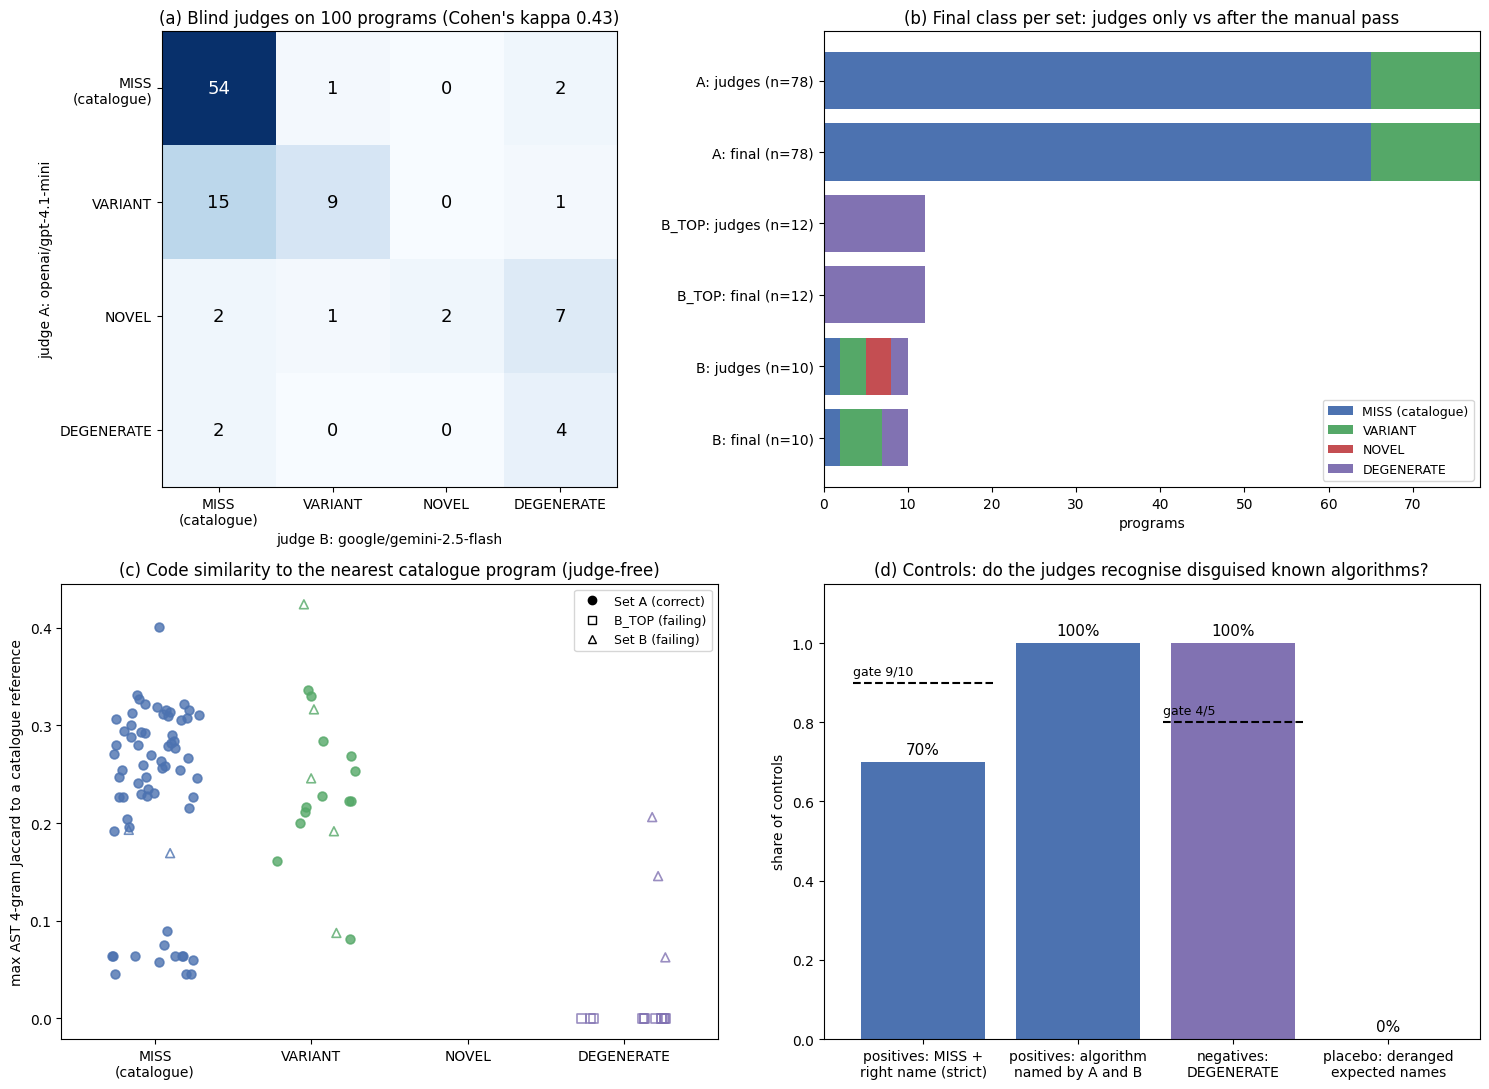

In [24]:
from matplotlib.lines import Line2D

CLS = ["LABELLER_MISS", "CATALOGUE_VARIANT", "NOVEL_ALGORITHM", "DEGENERATE_OR_HARDCODED"]
SHORT = {"LABELLER_MISS": "MISS\n(catalogue)", "CATALOGUE_VARIANT": "VARIANT", "NOVEL_ALGORITHM": "NOVEL",
         "DEGENERATE_OR_HARDCODED": "DEGENERATE"}
COL = {"LABELLER_MISS": "#4C72B0", "CATALOGUE_VARIANT": "#55A868", "NOVEL_ALGORITHM": "#C44E52",
       "DEGENERATE_OR_HARDCODED": "#8172B2"}
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) judge A vs judge B confusion matrix
both = tab[tab["judge_A"].notna() & tab["judge_B"].notna()]
cm = pd.crosstab(both["judge_A"], both["judge_B"]).reindex(index=CLS, columns=CLS, fill_value=0)
ax = axes[0, 0]
ax.imshow(cm.values, cmap="Blues")
for i in range(len(CLS)):
    for j in range(len(CLS)):
        v = int(cm.values[i, j])
        ax.text(j, i, v, ha="center", va="center", fontsize=13, color="white" if v > cm.values.max() / 2 else "black")
ax.set_xticks(range(len(CLS)), [SHORT[c] for c in CLS])
ax.set_yticks(range(len(CLS)), [SHORT[c] for c in CLS])
ax.set_xlabel("judge B: google/gemini-2.5-flash")
ax.set_ylabel("judge A: openai/gpt-4.1-mini")
ax.set_title(f"(a) Blind judges on {len(both)} programs (Cohen's kappa {nov['kappa_A_B']:.2f})")

# (b) class composition per set: judges only vs final
ax = axes[0, 1]
labels, mat = [], []
for s in ("A", "B_TOP", "B"):
    sub = tab[tab["set"] == s]
    for col, tag in (("final_judge_class", "judges"), ("final_class", "final")):
        labels.append(f"{s}: {tag} (n={len(sub)})")
        mat.append([int((sub[col] == c).sum()) for c in CLS])
mat = np.array(mat)
left = np.zeros(len(mat))
for k, c in enumerate(CLS):
    ax.barh(range(len(mat)), mat[:, k], left=left, color=COL[c], label=SHORT[c].replace("\n", " "))
    left += mat[:, k]
ax.set_yticks(range(len(mat)), labels)
ax.invert_yaxis()
ax.set_xlabel("programs")
ax.legend(fontsize=9, loc="lower right")
ax.set_title("(b) Final class per set: judges only vs after the manual pass")

# (c) AST 4-gram Jaccard to the nearest catalogue reference, by final class
ax = axes[1, 0]
rng_plot = np.random.default_rng(0)
for k, c in enumerate(CLS):
    for s, mk, fill in (("A", "o", True), ("B_TOP", "s", False), ("B", "^", False)):
        v = tab[(tab["final_class"] == c) & (tab["set"] == s)]["max_ast4_jaccard"].dropna().to_numpy()
        if len(v):
            ax.scatter(k + rng_plot.uniform(-0.28, 0.28, len(v)), v, marker=mk, s=40,
                       facecolor=COL[c] if fill else "none", edgecolor=COL[c], linewidth=1.2, alpha=0.8)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="k", label="Set A (correct)"),
                   Line2D([], [], marker="s", ls="", mfc="none", color="k", label="B_TOP (failing)"),
                   Line2D([], [], marker="^", ls="", mfc="none", color="k", label="Set B (failing)")], fontsize=9)
ax.set_xticks(range(len(CLS)), [SHORT[c] for c in CLS])
ax.set_xlim(-0.6, len(CLS) - 0.4)
ax.set_ylabel("max AST 4-gram Jaccard to a catalogue reference")
ax.set_title("(c) Code similarity to the nearest catalogue program (judge-free)")

# (d) controls
ax = axes[1, 1]
cc, pl = nov["controls"], nov["controls_placebo_wrong_names"]
vals = [cc["pos_hits"] / cc["pos_n"], nov["controls_identity_both_judges"] / cc["pos_n"], cc["neg_hits"] / cc["neg_n"],
        pl["pos_hits"] / pl["pos_n"]]
names = ["positives: MISS +\nright name (strict)", "positives: algorithm\nnamed by A and B", "negatives:\nDEGENERATE",
         "placebo: deranged\nexpected names"]
ax.bar(range(4), vals, color=["#4C72B0", "#4C72B0", "#8172B2", "#999999"])
for i, v in enumerate(vals):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center", fontsize=11)
ax.hlines([0.9, 0.8], [-0.45, 1.55], [0.45, 2.45], colors="k", linestyles="--")
ax.text(-0.45, 0.92, "gate 9/10", fontsize=9)
ax.text(1.55, 0.82, "gate 4/5", fontsize=9)
ax.set_xticks(range(4), names)
ax.set_ylim(0, 1.15)
ax.set_ylabel("share of controls")
ax.set_title("(d) Controls: do the judges recognise disguised known algorithms?")

plt.tight_layout()
plt.savefig(FIGS / "novelty_audit_demo.png", dpi=110)
plt.show()

### The TOP ban: "avoidance" without a new algorithm

exp9's `multi:TOP` condition bans the four most common grid-search algorithms at once: BFS, DFS, greedy best-first search and IDDFS. 13 of its 100 programs were labelled outside the banned set, which looked like the model escaping the ban. The audit shows what these 13 programs are:
- the 12 B_TOP programs, all failing the tests and all judged degenerate. None of them even parses as Python;
- one correct program in Set A, which the judges identify as a unit-weight Dijkstra, a known algorithm.

The multi-ban table below needs exp9's 400 per-program rows, which are not shipped. It is therefore the full-run table, carried into `novelty_audit.json` by the `DEMO` fallback.

exp9 multi:TOP programs outside the banned set in this demo: 13 (12 judged degenerate, 12 failing; correct ones: ['unit-weight Dijkstra'])
                item_id   set  passed                 judge_A                 judge_B                 judge_C             final_class        closest_known
    A|t1|2009762f592061     A    True           LABELLER_MISS           LABELLER_MISS                    None           LABELLER_MISS unit-weight Dijkstra
B_TOP|t1|60b2095c453143 B_TOP   False DEGENERATE_OR_HARDCODED DEGENERATE_OR_HARDCODED                    None DEGENERATE_OR_HARDCODED                 none
B_TOP|t1|cfe9b350e6a8ba B_TOP   False DEGENERATE_OR_HARDCODED           LABELLER_MISS DEGENERATE_OR_HARDCODED DEGENERATE_OR_HARDCODED                  BFS
B_TOP|t1|d7fcc2ef70b867 B_TOP   False DEGENERATE_OR_HARDCODED DEGENERATE_OR_HARDCODED                    None DEGENERATE_OR_HARDCODED                  BFS
B_TOP|t1|2e9267b512cdf0 B_TOP   False DEGENERATE_OR_HARDCODED           LABELLER_MISS 

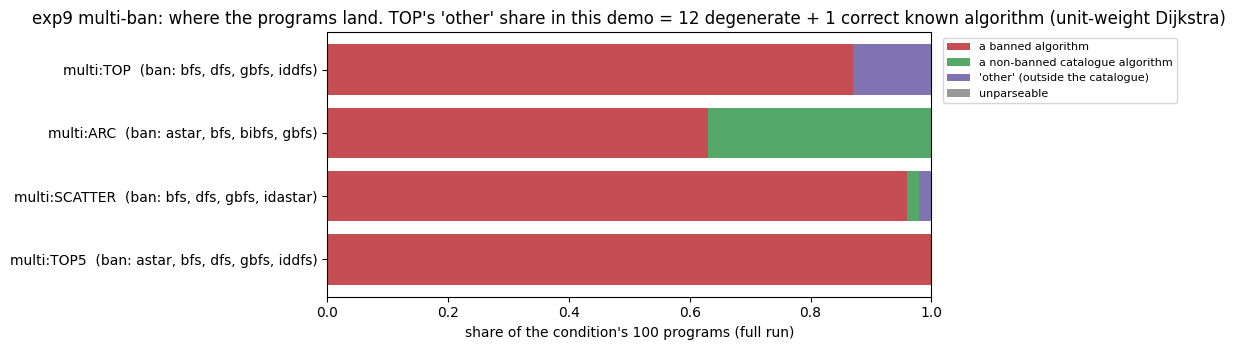

In [25]:
top = tab[tab["conditions"].apply(lambda cs: "multi:TOP" in cs)]
n_deg = int((top["final_class"] == "DEGENERATE_OR_HARDCODED").sum())
known = top[top["set"] == "A"]["closest_known"].tolist()
print(f"exp9 multi:TOP programs outside the banned set in this demo: {len(top)} "
      f"({n_deg} judged degenerate, {int((~top['passed'].astype(bool)).sum())} failing; correct ones: {known})")
print(top[["item_id", "set", "passed", "judge_A", "judge_B", "judge_C", "final_class", "closest_known"]].to_string(index=False))

av = pd.DataFrame(nov["multiban_avoidance"])
print("\nexp9 multi-ban conditions (full-run table, 100 programs each):")
print(av[["condition", "banned_set", "banned_share", "nonbanned_catalogue_share", "other_share", "unparseable_share",
          "avoidance_raw", "avoidance_corrected"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 3.6))
parts = [("banned_share", "a banned algorithm", "#C44E52"),
         ("nonbanned_catalogue_share", "a non-banned catalogue algorithm", "#55A868"),
         ("other_share", "'other' (outside the catalogue)", "#8172B2"), ("unparseable_share", "unparseable", "#999999")]
ylab = [f"{c}  (ban: {', '.join(b)})" for c, b in zip(av["condition"], av["banned_set"])]
left = np.zeros(len(av))
for col, lab, colr in parts:
    ax.barh(ylab, av[col], left=left, color=colr, label=lab)
    left += av[col].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of the condition's 100 programs (full run)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set_title(f"exp9 multi-ban: where the programs land. TOP's 'other' share in this demo = {n_deg} degenerate "
             f"+ {len(known)} correct known algorithm ({', '.join(map(str, known))})")
plt.tight_layout()
plt.show()

### Two programs, three judges, one human reader

To make the judging concrete, the cell prints two programs, each with the judges' mechanism summaries and the manual verdict:
1. **A failing Set B program that both blind judges called NOVEL.** The manual pass overrides them and records why.
2. **The one correct program the TOP ban produced outside the banned set.** This is the most "creative" outcome of that condition.

In [26]:
code_by_id = {it["item_id"]: it["code"] for k in ("A", "B_TOP", "B") for it in data["selection"][k]}
verdicts = defaultdict(dict)
for r in data["judge_cache"]:
    verdicts[r["item_id"]][r["judge"]] = r


def show(row, max_chars=2500):
    print("=" * 110)
    print(f"{row['item_id']} | task {row['task']} | models {row['models']} | conditions {row['conditions']} | "
          f"passes the hidden tests: {row['passed']}\n")
    print(code_by_id[row["item_id"]][:max_chars])
    for j in "ABC":
        r = verdicts[row["item_id"]].get(j)
        if r:
            p = r["parsed"]
            print(f"\njudge {j} ({r['model']}): {p['class']} (confidence {p.get('confidence')}; closest known: "
                  f"{p.get('closest_known_algorithm')})\n  {p.get('mechanism_summary')}")
    print(f"\nfinal judge class: {row['final_judge_class']} ({row['final_how']})  ->  final class: {row['final_class']}")
    print(f"manual pass: {row['manual_class']}: {row['manual_reason']}\n")


both_novel = tab[(tab["judge_A"] == "NOVEL_ALGORITHM") & (tab["judge_B"] == "NOVEL_ALGORITHM") & tab["manual_override"].notna()]
show((both_novel if len(both_novel) else tab).iloc[0])
top_correct = tab[(tab["set"] == "A") & tab["conditions"].apply(lambda cs: "multi:TOP" in cs)]
show((top_correct if len(top_correct) else tab[tab["set"] == "A"]).iloc[0])

B|t1|8c44b412fa9c85 | task t1 | models ['Qwen/Qwen3-8B'] | conditions ['ban:bfs'] | passes the hidden tests: False


def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0]) if rows > 0 else 0

    # Directions: up, down, left, right
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    # Check if a position is valid
    def is_valid(r, c):
        return 0 <= r < rows and 0 <= c < cols and grid[r][c] == '.'

    # Backtrack to find a path from the goal to the start
    def backtrack(pos, path):
        if pos == start:
            return path
        r, c = pos
        for dr, dc in directions:
            nr, nc = r + dr, c + dc
            if is_valid(nr, nc) and (nr, nc) in path:
                new_path = path[:]
                new_path.append((nr, nc))
                result = backtrack((nr, nc), new_path)
                if result is not None:
                    return result
        return None

    # Initialize the path with the start position
    path =

## What this shows

- **No novel algorithms.** The audit covers both models, 11 artifacts and every condition, including explicit "invent a new algorithm" instructions. All **78 unique correct programs** that fell outside the algorithm catalogue turn out to be known algorithms: 65 `LABELLER_MISS` and 13 `CATALOGUE_VARIANT`. Most are a unit-weight Dijkstra on the grid or a counting sort, and **none** is NOVEL. With 0 of 78, the rule-of-three 95% upper bound on the novel share of this population is **3/78 ≈ 0.038**.
- **Bans make the model substitute, not invent.** Pushed off its favourite algorithm, the model writes another textbook algorithm, or failing degenerate code. The TOP ban's 13% "avoidance" is 12 degenerate failing programs plus one unit-weight Dijkstra.
- **The judges are only fairly reliable, which is why there is a tie-break and a manual read.** Over all 228 items, kappa between the two blind judges is 0.38. Most of the disagreement comes from gpt-4.1-mini calling broken code NOVEL (panel a). On disguised catalogue programs, both judges name the right algorithm 10/10 times. Three of those (IDDFS, Dial, bidirectional Dijkstra) are classed as a "variant" rather than the catalogue entry itself, so the strict gate fails at 7/10. No control is called NOVEL, and the deranged-name placebo collapses to 0/10, as it must.
- **Reproducing the full audit.** In the artifact repository, run `uv run eval.py --section judges` and then `uv run eval.py --section novelty`, over all 228 items. This needs the run-volume dependencies (`common/paths.py: dep_root()`). `OPENROUTER_API_KEY` is needed only for items missing from `audit/judge_cache.jsonl`.